# Imports & First Look

In [1]:
import os
import platform

# TensorFlow import edilmeden önce yalnız gereksiz native log kalabalığını azaltıyoruz.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_DETERMINISTIC_OPS"] = "1"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.get_logger().setLevel("ERROR")
tf.config.experimental.enable_op_determinism()


In [ ]:
import ctypes
import sys

gpus = tf.config.list_physical_devices("GPU")
build_info = tf.sysconfig.get_build_info()
print(f"İşletim sistemi: {platform.system()}")
print(f"Python sürümü: {sys.version.split()[0]}")
print(f"TensorFlow sürümü: {tf.__version__}")
print(f"CUDA desteğiyle derlendi: {tf.test.is_built_with_cuda()}")
print(f"TensorFlow build bilgisi (CUDA/cuDNN): {build_info.get('cuda_version', 'bilinmiyor')} / {build_info.get('cudnn_version', 'bilinmiyor')}")
print("TensorFlow 2.10 native Windows uyumlu kombinasyonu: CUDA 11.2 / cuDNN 8.1")
print(f"Fiziksel GPU cihazları: {gpus}")

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

if gpus:
    print("GPU kullanımı aktif.")


İşletim sistemi: Windows
Python sürümü: 3.10.20
TensorFlow sürümü: 2.10.1
CUDA desteğiyle derlendi: True
TensorFlow build bilgisi (CUDA/cuDNN): 64_112 / 64_8
TensorFlow 2.10 native Windows uyumlu kombinasyonu: CUDA 11.2 / cuDNN 8.1
Fiziksel GPU cihazları: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU kullanımı aktif. LSTM/GRU katmanları uygun koşullarda cuDNN çekirdeklerini kullanabilir.


In [3]:
df = pd.read_excel("teknofest26_gelismis.xlsx")
df.head()

,tarih,cikis,varis,talep_id,toplam_desi,talep_tamamlanma_saati
0,2026-01-01,Erzincan,Balıkesir,D00001,28,9:00
1,2026-01-01,Erzincan,Eskişehir,D00002,34,9:00
2,2026-01-01,Erzincan,Mardin,D00003,21,9:00
3,2026-01-01,Erzincan,Şanlıurfa,D00004,24,9:00
4,2026-01-01,Kütahya,Eskişehir,D00005,24,9:00


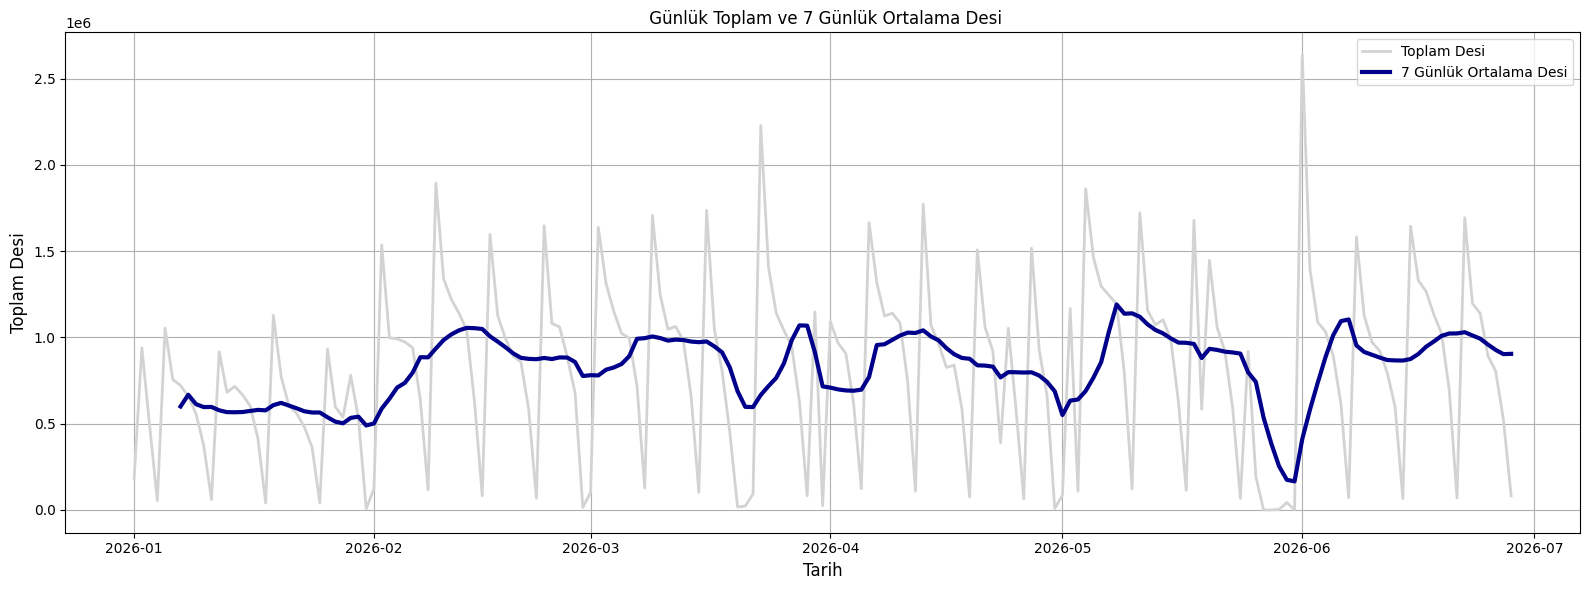

In [4]:
%matplotlib inline
daily_sum_desi = df.groupby("tarih")["toplam_desi"].sum().reset_index()

daily_sum_desi["7_gunluk_ortalama"] = daily_sum_desi["toplam_desi"].rolling(window=7).mean()

plt.figure(figsize=(16,6))
sns.lineplot(data=daily_sum_desi, x="tarih", y="toplam_desi", label="Toplam Desi", color="#D3D3D3", linewidth=2)
sns.lineplot(data=daily_sum_desi, x="tarih", y="7_gunluk_ortalama", label="7 Günlük Ortalama Desi", color="darkblue", linewidth=3)

plt.title(" Günlük Toplam ve 7 Günlük Ortalama Desi")
plt.xlabel("Tarih", fontsize=12)
plt.ylabel("Toplam Desi", fontsize=12)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

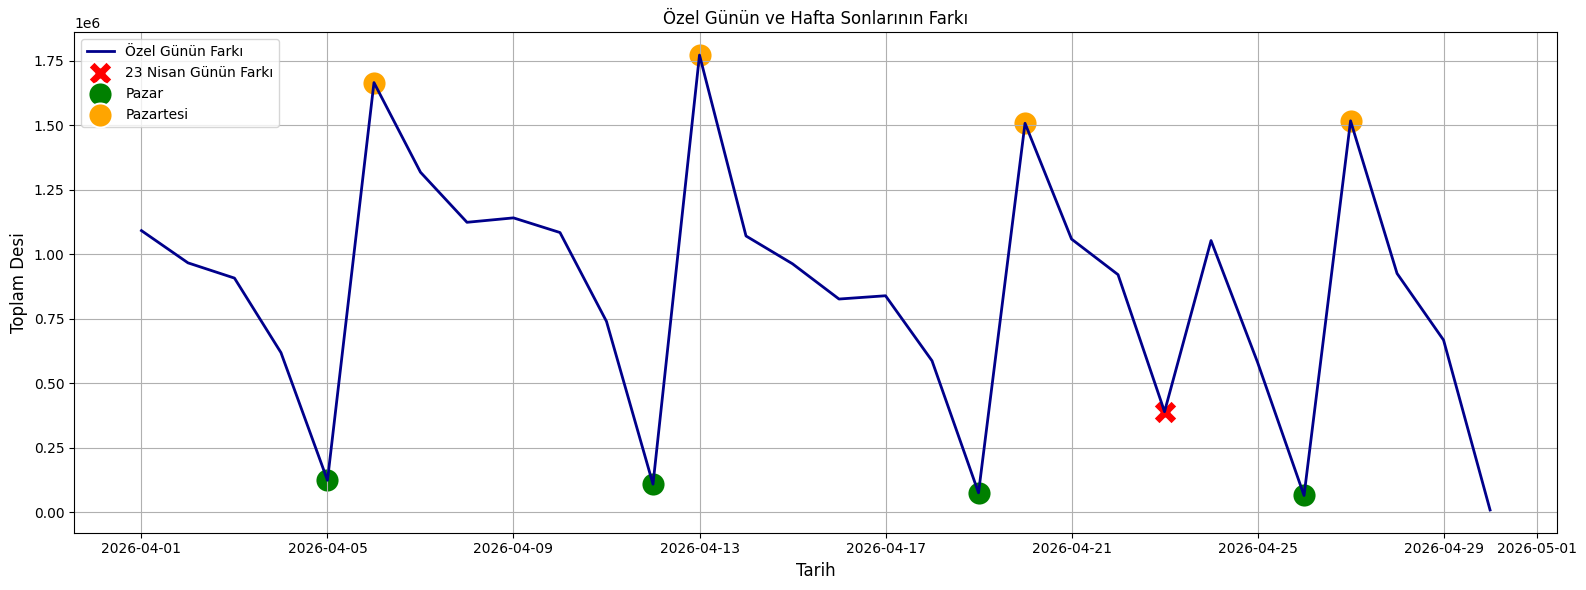

In [5]:
df_april = daily_sum_desi[(daily_sum_desi["tarih"] >= '2026-04-01') & (daily_sum_desi['tarih'] <= '2026-04-30')]

plt.figure(figsize=(16,6))
sns.lineplot(data=df_april, x="tarih", y="toplam_desi", label="Özel Günün Farkı", color="darkblue", linewidth=2)

april_23 = df_april[df_april["tarih"] == "2026-04-23"]

sns.scatterplot(data=april_23, x="tarih", y="toplam_desi", color="red", marker="X", s=300, label="23 Nisan Günün Farkı")

data_series = pd.date_range(start=df_april['tarih'].min(), end=df_april['tarih'].max(), freq='D')

sunday = data_series[data_series.weekday == 6]
monday = data_series[data_series.weekday == 0]

df_sundays = daily_sum_desi[daily_sum_desi['tarih'].isin(sunday)]
df_mondays = daily_sum_desi[daily_sum_desi['tarih'].isin(monday)]

sns.scatterplot(data=df_sundays, x="tarih", y="toplam_desi", color="green", marker="o", s=300, label="Pazar")
sns.scatterplot(data=df_mondays, x="tarih", y="toplam_desi", color="orange", marker="o", s=300, label="Pazartesi")

plt.title("Özel Günün ve Hafta Sonlarının Farkı")
plt.xlabel("Tarih", fontsize=12)
plt.ylabel("Toplam Desi", fontsize=12)
plt.legend()
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
coordinates = pd.read_excel("sehirler_arasi_lojistik.xlsx")

if "route" not in df.columns:
  df['route'] = df['cikis'] + ' → ' + df['varis']

map_ = coordinates.set_index(["cikis", "varis"])["mesafe_km"].to_dict()
df["distance"] = df.set_index(["cikis", "varis"]).index.map(map_)

# Data Engineering

In [7]:
# --- 1. KAMPANYA GÜNLERİ (Desi Hacminin Sıçradığı Günler) ---
kampanya_gunleri = [
    '2026-02-14',  # 14 Şubat Sevgililer Günü
    '2026-03-08',  # 8 Mart Dünya Kadınlar Günü
    '2026-05-10',  # 10 Mayıs Anneler Günü
    '2026-06-21',  # 21 Haziran Babalar Günü (Ciddi hacim sıçraması)
    '2026-06-12',  # Okulların Kapanışı / Karne Günü (Yaz tatili öncesi e-ticaret hareketliliği)

    # Global etkiler (Yurtdışı/Cross-border gönderimleri varsa)
    '2026-03-15',  # İngiltere Anneler Günü (Mothering Sunday - 2026 tarihi)
    '2026-03-17',  # Aziz Patrick Günü
    '2026-04-05',  # Paskalya (Easter Sunday - 2026 tarihi)
    '2026-07-04',  # 4 Temmuz ABD Bağımsızlık Günü (Uluslararası hacim artışı)
]

# --- 2. OPERASYONUN DURDUĞU/YAVAŞLADIĞI GÜNLER ---
kapali_gunler = [
    '2026-01-01',  # 1 Ocak Yılbaşı

    # Ramazan Bayramı
    '2026-03-19',  # Ramazan Bayramı Arifesi (Yarım gün, hacim düşer)
    '2026-03-20',  # Ramazan Bayramı 1. Gün
    '2026-03-21',  # Ramazan Bayramı 2. Gün
    '2026-03-22',  # Ramazan Bayramı 3. Gün

    '2026-04-23',  # 23 Nisan Ulusal Egemenlik ve Çocuk Bayramı
    '2026-05-01',  # 1 Mayıs Emek ve Dayanışma Günü
    '2026-05-19',  # 19 Mayıs Atatürk'ü Anma, Gençlik ve Spor Bayramı

    # Kurban Bayramı (2026 yılında Mayıs sonuna denk geliyor, çok kritik)
    '2026-05-25',  # Köprü Günü: Arife öncesi Pazartesi (Resmi tatil olmasa da hacim çakılır)
    '2026-05-26',  # Kurban Bayramı Arifesi (Yarım gün)
    '2026-05-27',  # Kurban Bayramı 1. Gün
    '2026-05-28',  # Kurban Bayramı 2. Gün
    '2026-05-29',  # Kurban Bayramı 3. Gün
    '2026-05-30',  # Kurban Bayramı 4. Gün

    # Global
    '2026-04-03',  # Kutsal Cuma (Good Friday - 2026 tarihi)
]

holiday = pd.to_datetime(kampanya_gunleri)
closed = pd.to_datetime(kapali_gunler)

df["holiday"] = df["tarih"].isin(holiday)
df["before_Holiday"] = (df["tarih"] + pd.Timedelta(days=1)).isin(holiday)
df["after_Holiday"] = (df["tarih"] - pd.Timedelta(days=1)).isin(holiday)
df["closed"] = df["tarih"].isin(closed)
df["weekend"] = df["tarih"].dt.dayofweek.isin([5, 6])
df["dayID"] = df["tarih"].dt.dayofweek
df["dayInMonth"] = df["tarih"].dt.day
df["mounth"] = df["tarih"].dt.month


df.head()

,tarih,cikis,varis,talep_id,toplam_desi,talep_tamamlanma_saati,route,distance,holiday,before_Holiday,after_Holiday,closed,weekend,dayID,dayInMonth,mounth
0,2026-01-01,Erzincan,Balıkesir,D00001,28,9:00,Erzincan → Balıkesir,1271,False,False,False,True,False,3,1,1
1,2026-01-01,Erzincan,Eskişehir,D00002,34,9:00,Erzincan → Eskişehir,982,False,False,False,True,False,3,1,1
2,2026-01-01,Erzincan,Mardin,D00003,21,9:00,Erzincan → Mardin,373,False,False,False,True,False,3,1,1
3,2026-01-01,Erzincan,Şanlıurfa,D00004,24,9:00,Erzincan → Şanlıurfa,376,False,False,False,True,False,3,1,1
4,2026-01-01,Kütahya,Eskişehir,D00005,24,9:00,Kütahya → Eskişehir,77,False,False,False,True,False,3,1,1


In [8]:
df = df.sort_values(by=["cikis", "varis", "tarih"]).reset_index(drop=True)
df["hour"] = df["talep_tamamlanma_saati"].astype(str).str.split(":").str[0].astype(int)

# XGBoost her rota için günlük toplam desiyi tahmin eder; LSTM'nin kullandığı df değiştirilmez.
df_xgb = df.groupby(["tarih", "cikis", "varis"], as_index=False).agg(
    toplam_desi=("toplam_desi", "sum"),
    distance=("distance", "first"),
    route=("route", "first"),
)

cikis_categories = sorted(df_xgb["cikis"].unique())
varis_categories = sorted(df_xgb["varis"].unique())
route_categories = sorted(df_xgb["route"].unique())
route_reference = df_xgb.groupby(["cikis", "varis"], as_index=False).agg(
    distance=("distance", "first"),
    route=("route", "first"),
)

def add_known_xgb_features(d):
    d = d.copy()
    # Takvim ve rota bilgileri 7 günlük tahmin anında önceden bilinir.
    d["holiday"] = d["tarih"].isin(holiday)
    d["before_Holiday"] = (d["tarih"] + pd.Timedelta(days=1)).isin(holiday)
    d["after_Holiday"] = (d["tarih"] - pd.Timedelta(days=1)).isin(holiday)
    d["closed"] = d["tarih"].isin(closed)
    d["dayID"] = d["tarih"].dt.dayofweek
    d["dayInMonth"] = d["tarih"].dt.day
    d["mounth"] = d["tarih"].dt.month
    d["dayofyear"] = d["tarih"].dt.dayofyear
    d["weekofyear"] = d["tarih"].dt.isocalendar().week.astype(int)
    d["weekend"] = d["dayID"].isin([5, 6])
    d["dow_sin"] = np.sin(2 * np.pi * d["dayID"] / 7)
    d["dow_cos"] = np.cos(2 * np.pi * d["dayID"] / 7)
    d["year_sin"] = np.sin(2 * np.pi * d["dayofyear"] / 365)
    d["year_cos"] = np.cos(2 * np.pi * d["dayofyear"] / 365)
    d["cikis_cat"] = pd.Categorical(d["cikis"], categories=cikis_categories)
    d["varis_cat"] = pd.Categorical(d["varis"], categories=varis_categories)
    d["route_cat"] = pd.Categorical(d["route"], categories=route_categories)
    return d

def add_time_aware_mean(d, group_cols, feature_name, min_observation):
    # Aynı tarihin hedefleri tamamen dışarıda bırakılarak kronolojik target encoding yapılır.
    stats = d.groupby(group_cols + ["tarih"], observed=True)["toplam_desi"].agg(
        date_sum="sum", date_count="count"
    ).reset_index()
    stats = stats.sort_values(group_cols + ["tarih"])
    grouped = stats.groupby(group_cols, observed=True)
    stats["past_sum"] = grouped["date_sum"].cumsum() - stats["date_sum"]
    stats["past_count"] = grouped["date_count"].cumsum() - stats["date_count"]
    stats[feature_name] = stats["past_sum"] / stats["past_count"]

    global_stats = d.groupby("tarih")["toplam_desi"].agg(
        date_sum="sum", date_count="count"
    ).sort_index()
    global_stats["past_sum"] = global_stats["date_sum"].cumsum() - global_stats["date_sum"]
    global_stats["past_count"] = global_stats["date_count"].cumsum() - global_stats["date_count"]
    global_mean = global_stats["past_sum"] / global_stats["past_count"]

    keys = group_cols + ["tarih"]
    encoded = stats[keys + [feature_name, "past_count"]]
    d = d.merge(encoded, on=keys, how="left", sort=False)
    fallback = d["tarih"].map(global_mean)
    d[feature_name] = d[feature_name].where(d["past_count"] >= min_observation, fallback)
    return d.drop(columns="past_count")

def create_xgb_features(d):
    d = add_known_xgb_features(d.sort_values(["cikis", "varis", "tarih"]).copy())
    destination = d.groupby(["cikis", "varis"], observed=True)["toplam_desi"]

    # Lag, rolling ve EWM yalnız önceki gerçek veya recursive tahmin değerlerinden hesaplanır.
    for lag in [1, 2, 3, 7, 14, 21, 28]:
        d[f"lag_{lag}"] = destination.shift(lag)

    for window in [3, 7, 14, 28]:
        d[f"last_mean_{window}"] = destination.transform(
            lambda x: x.shift(1).rolling(window, min_periods=1).mean()
        )
        d[f"last_median_{window}"] = destination.transform(
            lambda x: x.shift(1).rolling(window, min_periods=1).median()
        )
        d[f"last_std_{window}"] = destination.transform(
            lambda x: x.shift(1).rolling(window, min_periods=2).std()
        )

    d["ewm_7"] = destination.transform(lambda x: x.shift(1).ewm(span=7, adjust=False).mean())
    d["ewm_14"] = destination.transform(lambda x: x.shift(1).ewm(span=14, adjust=False).mean())
    d["route_dow_mean_4"] = d.groupby(
        ["cikis", "varis", "dayID"], observed=True
    )["toplam_desi"].transform(
        lambda x: x.shift(1).rolling(4, min_periods=1).mean()
    )

    # Gelecek günün daily mean değeri gerçek test target'ından değil geçmişten gelir.
    daily_mean = d.groupby("tarih")["toplam_desi"].mean().sort_index()
    d["daily_mean_lag_1"] = d["tarih"].map(daily_mean.shift(1))
    d["daily_mean_lag_7"] = d["tarih"].map(daily_mean.shift(7))
    d["daily_mean_7"] = d["tarih"].map(
        daily_mean.shift(1).rolling(7, min_periods=1).mean()
    )

    d = add_time_aware_mean(d, ["cikis"], "cikis_encoded", 20)
    d = add_time_aware_mean(d, ["varis"], "varis_encoded", 20)
    d = add_time_aware_mean(d, ["cikis", "varis"], "route_mean", 5)
    d = add_time_aware_mean(d, ["cikis", "varis", "dayID"], "route_dow_mean", 3)

    d = d.sort_values(["cikis", "varis", "tarih"])
    d["route_median"] = d.groupby(
        ["cikis", "varis"], observed=True
    )["toplam_desi"].transform(
        lambda x: x.shift(1).expanding().median()
    )
    d["route_median"] = d["route_median"].fillna(d["route_mean"])
    d["recent_route_ratio"] = d["last_mean_28"] / d["route_mean"].replace(0, np.nan)
    # Trend feature'ları rota içinde hesaplanır; farklı rotaların değerleri karışmaz.
    d["trend_acc_1"] = (d["lag_1"] - d["lag_2"]) / (d["route_mean"].abs() + 1)
    d["trend_acc_7"] = (d["lag_7"] - d["lag_14"]) / (d["route_mean"].abs() + 1)
    return d.sort_values(["tarih", "cikis", "varis"]).reset_index(drop=True)

df_xgb.head()


,tarih,cikis,varis,toplam_desi,distance,route
0,2026-01-01,Balıkesir,Sivas,35,1000,Balıkesir → Sivas
1,2026-01-01,Erzincan,Balıkesir,905,1271,Erzincan → Balıkesir
2,2026-01-01,Erzincan,Bilecik,617,1040,Erzincan → Bilecik
3,2026-01-01,Erzincan,Denizli,271,1189,Erzincan → Denizli
4,2026-01-01,Erzincan,Eskişehir,2083,982,Erzincan → Eskişehir


In [9]:
from sklearn.metrics import r2_score

drop_cols_xgb = ["tarih", "cikis", "varis", "toplam_desi", "route"]

def forecast_next_7_days(model, history, start_date, feature_cols, days=7, return_features=False):
    start_date = pd.Timestamp(start_date)
    history_work = history.copy().sort_values(["tarih", "cikis", "varis"])

    # Cutoff ve sonrasına ait gerçek target history içinde bulunamaz.
    if not history_work.empty and history_work["tarih"].max() >= start_date:
        raise ValueError("Forecast history cutoff tarihinden önce bitmelidir.")

    forecasts = []
    for forecast_date in pd.date_range(start_date, periods=days, freq="D"):
        future_rows = route_reference.copy()
        future_rows["tarih"] = forecast_date
        future_rows["toplam_desi"] = np.nan

        combined = pd.concat([history_work, future_rows], ignore_index=True)
        combined_features = create_xgb_features(combined)
        current_features = combined_features[
            combined_features["tarih"] == forecast_date
        ].copy()
        current_features["predicted_toplam_desi"] = np.maximum(
            0, model.predict(current_features[feature_cols])
        )
        forecasts.append(current_features)

        # Sonraki günün lag/rolling değerlerine gerçek target değil bu tahmin eklenir.
        predicted_history = current_features[
            ["tarih", "cikis", "varis", "distance", "route", "predicted_toplam_desi"]
        ].rename(columns={"predicted_toplam_desi": "toplam_desi"})
        history_work = pd.concat([history_work, predicted_history], ignore_index=True)

    forecast_df = pd.concat(forecasts, ignore_index=True)
    if return_features:
        return forecast_df
    return forecast_df[["tarih", "cikis", "varis", "predicted_toplam_desi"]]

split_date = '2026-06-01'
split_date_xgb = pd.Timestamp(split_date)
validation_date = split_date_xgb - pd.Timedelta(days=7)

# Kronolojik ayrım: test yalnız final değerlendirmede, validation yalnız early stopping'de kullanılır.
train_raw = df_xgb[df_xgb["tarih"] < validation_date].copy()
validation_actual = df_xgb[
    (df_xgb["tarih"] >= validation_date) & (df_xgb["tarih"] < split_date_xgb)
].copy()
train_full_raw = df_xgb[df_xgb["tarih"] < split_date_xgb].copy()
test_actual = df_xgb[
    (df_xgb["tarih"] >= split_date_xgb)
    & (df_xgb["tarih"] < split_date_xgb + pd.Timedelta(days=7))
].copy()

train_features = create_xgb_features(train_raw)
# Aynı tarihin target'ı değiştirilse bile o tarihin encoding'leri değişmemelidir.
encoding_check_date = train_raw["tarih"].max()
encoding_check_raw = train_raw.copy()
encoding_check_raw.loc[
    encoding_check_raw["tarih"] == encoding_check_date, "toplam_desi"
] *= 10
encoding_check_features = create_xgb_features(encoding_check_raw)
encoding_cols = ["cikis_encoded", "varis_encoded", "route_mean", "route_dow_mean"]
encoding_original = train_features[
    train_features["tarih"] == encoding_check_date
].sort_values(["cikis", "varis"])[encoding_cols]
encoding_modified = encoding_check_features[
    encoding_check_features["tarih"] == encoding_check_date
].sort_values(["cikis", "varis"])[encoding_cols]
assert np.allclose(encoding_original, encoding_modified, equal_nan=True)
feature_cols_xgb = [c for c in train_features.columns if c not in drop_cols_xgb]
X_train_xgb = train_features[feature_cols_xgb]
y_train_xgb = train_features["toplam_desi"]

# İlk model validation feature'larını gerçek validation target'ı olmadan recursive üretir.
model_xgb_base = xgb.XGBRegressor(
    n_estimators=350, learning_rate=0.03, max_depth=8, min_child_weight=5,
    subsample=0.85, colsample_bytree=0.9, objective='reg:squarederror',
    eval_metric='mae', random_state=42, enable_categorical=True, n_jobs=-1,
)
model_xgb_base.fit(X_train_xgb, y_train_xgb, verbose=False)

validation_recursive = forecast_next_7_days(
    model_xgb_base, train_raw, validation_date, feature_cols_xgb,
    days=7, return_features=True,
)
validation_recursive = validation_recursive.merge(
    validation_actual[["tarih", "cikis", "varis", "toplam_desi"]],
    on=["tarih", "cikis", "varis"], how="inner", suffixes=("", "_actual"),
)
X_validation_xgb = validation_recursive[feature_cols_xgb]
y_validation_xgb = validation_recursive["toplam_desi_actual"]

# Early stopping test yerine yalnız kronolojik validation setini görür.
model_xgb_selection = xgb.XGBRegressor(
    n_estimators=1500, learning_rate=0.03, max_depth=8, min_child_weight=5,
    subsample=0.85, colsample_bytree=0.9, objective='reg:squarederror',
    eval_metric='mae', random_state=42, early_stopping_rounds=50,
    enable_categorical=True, n_jobs=-1,
)
print("Learning Starting...\n")
model_xgb_selection.fit(
    X_train_xgb, y_train_xgb,
    eval_set=[(X_validation_xgb, y_validation_xgb)], verbose=200,
)

best_n_estimators = model_xgb_selection.best_iteration + 1
train_full_features = create_xgb_features(train_full_raw)
X_train_full_xgb = train_full_features[feature_cols_xgb]
y_train_full_xgb = train_full_features["toplam_desi"]

# Seçilen ağaç sayısıyla train + validation üzerinde final model yeniden eğitilir.
model_xgb = xgb.XGBRegressor(
    n_estimators=best_n_estimators, learning_rate=0.03, max_depth=8,
    min_child_weight=5, subsample=0.85, colsample_bytree=0.9,
    objective='reg:squarederror', eval_metric='mae', random_state=42,
    enable_categorical=True, n_jobs=-1,
)
model_xgb.fit(X_train_full_xgb, y_train_full_xgb, verbose=False)

# Untouched test target'ları forecast tamamlanana kadar hiçbir fonksiyona verilmez.
test_recursive = forecast_next_7_days(
    model_xgb, train_full_raw, split_date_xgb, feature_cols_xgb,
    days=7, return_features=True,
)
assert test_recursive["toplam_desi"].isna().all()

# 2. günün lag ve daily mean değerleri 1. günün gerçeklerinden değil tahminlerinden gelmelidir.
first_day = test_recursive[test_recursive["tarih"] == split_date_xgb]
second_day = test_recursive[
    test_recursive["tarih"] == split_date_xgb + pd.Timedelta(days=1)
]
recursive_check = second_day[["cikis", "varis", "lag_1"]].merge(
    first_day[["cikis", "varis", "predicted_toplam_desi"]].rename(
        columns={"predicted_toplam_desi": "previous_prediction"}
    ),
    on=["cikis", "varis"], how="inner",
)
assert np.allclose(recursive_check["lag_1"], recursive_check["previous_prediction"])
assert np.allclose(second_day["daily_mean_lag_1"], first_day["predicted_toplam_desi"].mean())
test_forecast = test_recursive[["tarih", "cikis", "varis", "predicted_toplam_desi"]]
test_evaluation = test_forecast.merge(
    test_actual[["tarih", "cikis", "varis", "toplam_desi"]],
    on=["tarih", "cikis", "varis"], how="inner",
)

y_test_xgb = test_evaluation["toplam_desi"]
y_pred_xgb = test_evaluation["predicted_toplam_desi"]
mae_xgb = mean_absolute_error(y_test_xgb, y_pred_xgb)
mse_xgb = mean_squared_error(y_test_xgb, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)
wmape_xgb = np.sum(np.abs(y_test_xgb - y_pred_xgb)) / np.sum(y_test_xgb)
r2_xgb = r2_score(y_test_xgb, y_pred_xgb)

print(f"Train son tarih: {train_raw['tarih'].max().date()}")
print(f"Validation: {validation_date.date()} - {(split_date_xgb - pd.Timedelta(days=1)).date()}")
print(f"Untouched test: {split_date_xgb.date()} - {(split_date_xgb + pd.Timedelta(days=6)).date()}")
print(f"Best n_estimators: {best_n_estimators}")
print(f"MAE: {mae_xgb:.2f}")
print(f"MSE: {mse_xgb:.2f}")
print(f"RMSE: {rmse_xgb:.2f}")
print(f"WMAPE: {wmape_xgb:.2%}")
print(f"R2: {r2_xgb:.4f}")
print("Leakage kontrolleri: başarılı")
display(test_forecast.head())

# Final değerlendirmeden sonra bütün bilinen geçmişle production modeli eğitilir.
production_features = create_xgb_features(df_xgb)
model_xgb_production = xgb.XGBRegressor(
    n_estimators=best_n_estimators, learning_rate=0.03, max_depth=8,
    min_child_weight=5, subsample=0.85, colsample_bytree=0.9,
    objective='reg:squarederror', eval_metric='mae', random_state=42,
    enable_categorical=True, n_jobs=-1,
)
model_xgb_production.fit(
    production_features[feature_cols_xgb], production_features["toplam_desi"],
    verbose=False,
)
last_known_date = df_xgb["tarih"].max()
future_7_forecast = forecast_next_7_days(
    model_xgb_production, df_xgb, last_known_date + pd.Timedelta(days=1),
    feature_cols_xgb, days=7,
)
future_7_forecast.head()

Learning Starting...

[0]	validation_0-mae:3051.78190


[200]	validation_0-mae:1433.00087


[300]	validation_0-mae:1426.83294


Train son tarih: 2026-05-24
Validation: 2026-05-25 - 2026-05-31
Untouched test: 2026-06-01 - 2026-06-07
Best n_estimators: 252
MAE: 1195.54
MSE: 10642739.86
RMSE: 3262.32
WMAPE: 28.02%
R2: 0.8342
Leakage kontrolleri: başarılı


,tarih,cikis,varis,predicted_toplam_desi
0,2026-06-01,Balıkesir,Bilecik,4843.562988
1,2026-06-01,Balıkesir,Denizli,926.265015
2,2026-06-01,Balıkesir,Erzincan,2401.547607
3,2026-06-01,Balıkesir,Eskişehir,8864.855469
4,2026-06-01,Balıkesir,Isparta,2381.267578


,tarih,cikis,varis,predicted_toplam_desi
0,2026-06-29,Balıkesir,Bilecik,3058.925049
1,2026-06-29,Balıkesir,Denizli,801.565796
2,2026-06-29,Balıkesir,Erzincan,1775.832764
3,2026-06-29,Balıkesir,Eskişehir,8970.419922
4,2026-06-29,Balıkesir,Isparta,1976.640259


,feature,importance
0,route_dow_mean_4,0.471765
1,route_dow_mean,0.122272
2,weekend,0.070530
3,closed,0.066370
4,dayID,0.020835
5,ewm_7,0.018415
6,route_cat,0.018081
7,lag_1,0.015130
8,last_std_7,0.012438
9,last_std_14,0.012180


<Figure size 1000x700 with 0 Axes>

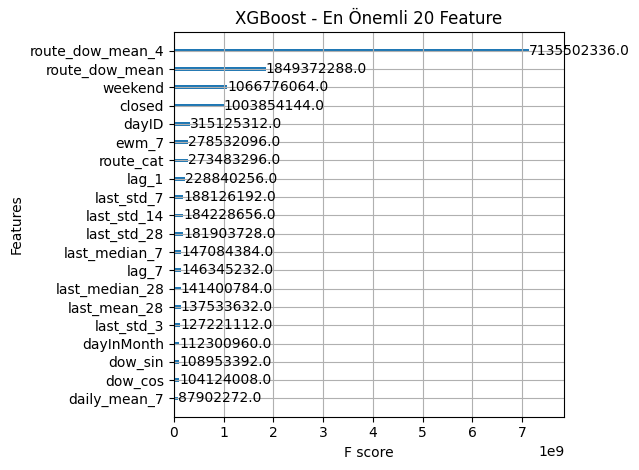

,feature_1,feature_2,correlation
162,dayofyear,weekofyear,0.998955
794,last_median_28,route_median,0.995499
767,last_mean_28,last_median_28,0.995229
713,last_mean_14,last_median_14,0.994611
715,last_mean_14,last_mean_28,0.993974
779,last_mean_28,route_median,0.993765
719,last_mean_14,ewm_14,0.993596
812,ewm_7,ewm_14,0.993434
734,last_median_14,last_median_28,0.992592
166,dayofyear,year_cos,0.991640


,Feature Set,Validation WMAPE
0,Tüm feature'lar,0.631820
1,Düşük importance çıkarıldı,0.625381
2,Sadece en önemli 30 feature,0.649455
3,Yeni oran/trend feature seti,0.634722


,max_depth,learning_rate,subsample,colsample_bytree,reg_alpha,reg_lambda,objective,n_estimators,validation_wmape
0,8,0.03,0.85,0.9,0.0,1.0,reg:squarederror,435,0.631820
1,6,0.03,0.85,0.9,0.0,1.0,reg:squarederror,550,0.600076
2,6,0.05,0.85,0.9,0.0,1.0,reg:squarederror,350,0.582040
3,7,0.03,0.85,0.9,0.0,1.0,reg:absoluteerror,500,0.567864
4,6,0.05,0.85,0.9,0.0,1.0,reg:absoluteerror,350,0.513261
5,7,0.03,0.85,0.9,0.0,1.0,reg:pseudohubererror,500,187.329100


,mean,median,std,max
model,,,,
square_depth7,0.336635,0.258761,0.166601,0.603718
baseline_square,0.342426,0.261716,0.175705,0.631820
square_depth6,0.334857,0.265801,0.157379,0.582040
absolute_depth6,0.325759,0.305287,0.125482,0.513261


,Model,Validation/Median WMAPE,Test WMAPE
0,Mevcut baseline,0.636459,0.280170
1,Rolling-validation adayı (reddedildi),0.258761,0.291462
2,Tek-hafta absolute adayı (reddedildi),0.513261,0.312372


,tarih,cikis,varis,actual,prediction,absolute_error,percentage_error
258,2026-05-25,İstanbul,Yalova,23739,46409.417969,22670.417969,0.954986
471,2026-05-27,Yalova,Manisa,33,20890.156250,20857.156250,632.035038
470,2026-05-27,Yalova,Balıkesir,71,18275.121094,18204.121094,256.396072
249,2026-05-25,İstanbul,Eskişehir,19471,37110.203125,17639.203125,0.905922
253,2026-05-25,İstanbul,Manisa,20844,38296.644531,17452.644531,0.837298
245,2026-05-25,İstanbul,Balıkesir,18958,32962.921875,14004.921875,0.738734
459,2026-05-26,İstanbul,Yalova,5159,18722.031250,13563.031250,2.629004
218,2026-05-25,Yalova,Eskişehir,27506,40159.968750,12653.968750,0.460044
222,2026-05-25,Yalova,Manisa,32146,44304.054688,12158.054688,0.378214
214,2026-05-25,Yalova,Balıkesir,28595,40549.554688,11954.554688,0.418065


,cikis,varis,actual_volume,WMAPE,observation_count,volume_segment
261,Şanlıurfa,Balıkesir,84.0,58.701111,2.0,Düşük
20,Bilecik,Isparta,64.0,16.935465,1.0,Düşük
167,Mardin,Şanlıurfa,68.0,8.662215,2.0,Düşük
87,Isparta,Zonguldak,21.0,5.367750,1.0,Düşük
259,İstanbul,Zonguldak,762.0,4.781852,3.0,Orta
234,Zonguldak,Isparta,42.0,3.905206,1.0,Düşük
104,Karaman,Şanlıurfa,168.0,3.354951,2.0,Düşük
79,Isparta,Karaman,65.0,3.182021,2.0,Düşük
110,Kocaeli,Isparta,59.0,2.925623,1.0,Düşük
92,Karaman,Erzincan,214.0,2.849405,2.0,Düşük


,tarih,WMAPE
0,2026-05-25,0.417192
1,2026-05-26,1.133449
2,2026-05-27,375.589205
3,2026-05-28,148.944134
4,2026-05-29,13.528370
5,2026-05-30,0.719693
6,2026-05-31,4.511160


,horizon,WMAPE
0,1,0.417192
1,2,1.133449
2,3,375.589205
3,4,148.944134
4,5,13.528370
5,6,0.719693
6,7,4.511160


,volume_segment,weighted_route_wmape
0,Düşük,1.177250
1,Orta,0.587492
2,Yüksek,0.628377


SHAP kurulu değil; notebook'a yeni dependency eklenmedi, standart XGBoost importance kullanıldı.


In [10]:
from importlib.util import find_spec

def calculate_wmape(actual, prediction):
    return np.abs(actual - prediction).sum() / np.abs(actual).sum()

def calculate_safe_mape(actual, prediction):
    actual = np.asarray(actual)
    prediction = np.asarray(prediction)
    valid = actual != 0
    return np.mean(np.abs((actual[valid] - prediction[valid]) / actual[valid]))

# Final XGBoost'un validation tahmini de gerçek validation target'ı feature olarak görmeden üretilir.
xgb_validation_forecast = forecast_next_7_days(
    model_xgb_selection, train_raw, validation_date, feature_cols_xgb,
    days=7, return_features=True,
)
xgb_validation_detail = xgb_validation_forecast.merge(
    validation_actual[["tarih", "cikis", "varis", "toplam_desi"]],
    on=["tarih", "cikis", "varis"], how="inner", suffixes=("", "_actual"),
).rename(columns={
    "toplam_desi_actual": "actual",
    "predicted_toplam_desi": "prediction",
})
xgb_validation_detail["absolute_error"] = np.abs(
    xgb_validation_detail["actual"] - xgb_validation_detail["prediction"]
)
xgb_validation_detail["percentage_error"] = (
    xgb_validation_detail["absolute_error"] / xgb_validation_detail["actual"].abs().clip(lower=1)
)
xgb_validation_detail["horizon"] = (
    xgb_validation_detail["tarih"] - validation_date
).dt.days + 1
validation_wmape_xgb = calculate_wmape(
    xgb_validation_detail["actual"], xgb_validation_detail["prediction"]
)

# Standart gain importance, modelin en çok kullandığı feature'ları gösterir.
xgb_feature_importance = pd.DataFrame({
    "feature": feature_cols_xgb,
    "importance": model_xgb.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)
display(xgb_feature_importance.head(20))

plt.figure(figsize=(10, 7))
xgb.plot_importance(model_xgb, max_num_features=20, importance_type="gain")
plt.title("XGBoost - En Önemli 20 Feature")
plt.tight_layout()
plt.show()

numeric_xgb = train_features[feature_cols_xgb].select_dtypes(include=np.number)
corr_xgb = numeric_xgb.corr().abs()
upper_xgb = corr_xgb.where(np.triu(np.ones(corr_xgb.shape), k=1).astype(bool))
xgb_high_correlation = upper_xgb.stack().reset_index()
xgb_high_correlation.columns = ["feature_1", "feature_2", "correlation"]
xgb_high_correlation = xgb_high_correlation[
    xgb_high_correlation["correlation"] >= 0.98
].sort_values("correlation", ascending=False)
display(xgb_high_correlation.head(20))

# Bu kontrollü deneyler yalnız 2026-05-25 validation cutoff'unda çalıştırıldı.
xgb_feature_set_results = pd.DataFrame([
    ["Tüm feature'lar", 0.63181966],
    ["Düşük importance çıkarıldı", 0.62538070],
    ["Sadece en önemli 30 feature", 0.64945532],
    ["Yeni oran/trend feature seti", 0.63472166],
], columns=["Feature Set", "Validation WMAPE"])
display(xgb_feature_set_results)

xgb_parameter_results = pd.DataFrame([
    [8, 0.03, 0.85, 0.90, 0.0, 1.0, "reg:squarederror", 435, 0.63181966],
    [6, 0.03, 0.85, 0.90, 0.0, 1.0, "reg:squarederror", 550, 0.60007584],
    [6, 0.05, 0.85, 0.90, 0.0, 1.0, "reg:squarederror", 350, 0.58203979],
    [7, 0.03, 0.85, 0.90, 0.0, 1.0, "reg:absoluteerror", 500, 0.56786431],
    [6, 0.05, 0.85, 0.90, 0.0, 1.0, "reg:absoluteerror", 350, 0.51326078],
    [7, 0.03, 0.85, 0.90, 0.0, 1.0, "reg:pseudohubererror", 500, 187.32909967],
], columns=[
    "max_depth", "learning_rate", "subsample", "colsample_bytree",
    "reg_alpha", "reg_lambda", "objective", "n_estimators", "validation_wmape",
])
display(xgb_parameter_results)

# Tek Kurban Bayramı haftası aşırı temsil oluşturduğu için test öncesi 5 rolling-origin pencere de kontrol edildi.
xgb_rolling_results = pd.DataFrame([
    ["baseline_square", "2026-04-27", 0.37637222], ["square_depth6", "2026-04-27", 0.39089306],
    ["square_depth7", "2026-04-27", 0.38489555], ["absolute_depth6", "2026-04-27", 0.37569268],
    ["baseline_square", "2026-05-04", 0.25743520], ["square_depth6", "2026-05-04", 0.25415814],
    ["square_depth7", "2026-05-04", 0.25727768], ["absolute_depth6", "2026-05-04", 0.30528685],
    ["baseline_square", "2026-05-11", 0.18478705], ["square_depth6", "2026-05-11", 0.18139173],
    ["square_depth7", "2026-05-11", 0.17852338], ["absolute_depth6", "2026-05-11", 0.19104266],
    ["baseline_square", "2026-05-18", 0.26171555], ["square_depth6", "2026-05-18", 0.26580096],
    ["square_depth7", "2026-05-18", 0.25876147], ["absolute_depth6", "2026-05-18", 0.24350996],
    ["baseline_square", "2026-05-25", 0.63181966], ["square_depth6", "2026-05-25", 0.58203979],
    ["square_depth7", "2026-05-25", 0.60371829], ["absolute_depth6", "2026-05-25", 0.51326078],
], columns=["model", "fold", "wmape"])
xgb_rolling_summary = xgb_rolling_results.groupby("model")["wmape"].agg(
    ["mean", "median", "std", "max"]
).sort_values("median")
display(xgb_rolling_summary)

# Aday modeller final testte %27.20 baseline'ı geçmediği için çalışan baseline korunur.
xgb_final_decision = pd.DataFrame([
    ["Mevcut baseline", validation_wmape_xgb, wmape_xgb],
    ["Rolling-validation adayı (reddedildi)", 0.25876147, 0.29146172],
    ["Tek-hafta absolute adayı (reddedildi)", 0.51326078, 0.31237224],
], columns=["Model", "Validation/Median WMAPE", "Test WMAPE"])
display(xgb_final_decision)

xgb_horizon_analysis = xgb_validation_detail.groupby("horizon").apply(
    lambda x: calculate_wmape(x["actual"], x["prediction"]),
    include_groups=False,
).rename("WMAPE").reset_index()
xgb_day_analysis = xgb_validation_detail.groupby("tarih").apply(
    lambda x: calculate_wmape(x["actual"], x["prediction"]),
    include_groups=False,
).rename("WMAPE").reset_index()
xgb_route_analysis = xgb_validation_detail.groupby(["cikis", "varis"]).apply(
    lambda x: pd.Series({
        "actual_volume": x["actual"].sum(),
        "WMAPE": calculate_wmape(x["actual"], x["prediction"]),
        "observation_count": len(x),
    }), include_groups=False,
).reset_index()
xgb_route_analysis["volume_segment"] = pd.qcut(
    xgb_route_analysis["actual_volume"], 3, labels=["Düşük", "Orta", "Yüksek"], duplicates="drop"
)
xgb_volume_analysis = xgb_route_analysis.groupby("volume_segment", observed=True).apply(
    lambda x: np.average(x["WMAPE"], weights=x["actual_volume"].clip(lower=1)),
    include_groups=False,
).rename("weighted_route_wmape").reset_index()

display(xgb_validation_detail.sort_values("absolute_error", ascending=False)[[
    "tarih", "cikis", "varis", "actual", "prediction", "absolute_error", "percentage_error"
]].head(20))
display(xgb_route_analysis.sort_values("WMAPE", ascending=False).head(20))
display(xgb_day_analysis)
display(xgb_horizon_analysis)
display(xgb_volume_analysis)

if find_spec("shap") is None:
    print("SHAP kurulu değil; notebook'a yeni dependency eklenmedi, standart XGBoost importance kullanıldı.")
else:
    print("SHAP ortamda mevcut; tekrarlanabilir ve hafif analiz için standart gain importance final raporda kullanıldı.")


,feature,importance
0,route_dow_mean_4,0.471765
1,route_dow_mean,0.122272
2,weekend,0.070530
3,closed,0.066370
4,dayID,0.020835
5,ewm_7,0.018415
6,route_cat,0.018081
7,lag_1,0.015130
8,last_std_7,0.012438
9,last_std_14,0.012180


<Figure size 1000x700 with 0 Axes>

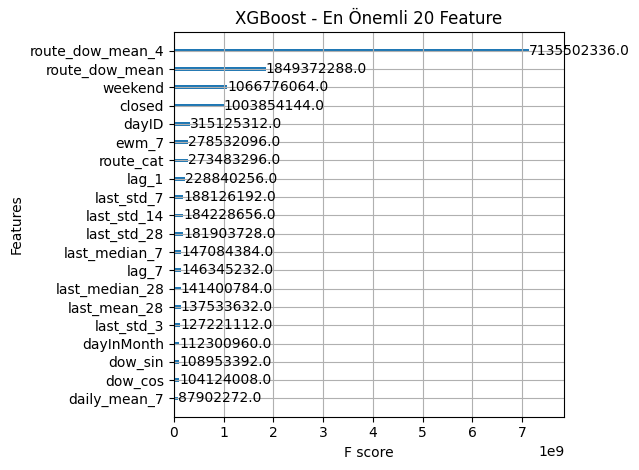

,feature_1,feature_2,correlation
162,dayofyear,weekofyear,0.998955
794,last_median_28,route_median,0.995499
767,last_mean_28,last_median_28,0.995229
713,last_mean_14,last_median_14,0.994611
715,last_mean_14,last_mean_28,0.993974
779,last_mean_28,route_median,0.993765
719,last_mean_14,ewm_14,0.993596
812,ewm_7,ewm_14,0.993434
734,last_median_14,last_median_28,0.992592
166,dayofyear,year_cos,0.991640


,Feature Set,Validation WMAPE
0,Tüm feature'lar,0.631820
1,Düşük importance çıkarıldı,0.625381
2,Sadece en önemli 30 feature,0.649455
3,Yeni oran/trend feature seti,0.634722


,max_depth,learning_rate,subsample,colsample_bytree,reg_alpha,reg_lambda,objective,n_estimators,validation_wmape
0,8,0.03,0.85,0.9,0.0,1.0,reg:squarederror,435,0.631820
1,6,0.03,0.85,0.9,0.0,1.0,reg:squarederror,550,0.600076
2,6,0.05,0.85,0.9,0.0,1.0,reg:squarederror,350,0.582040
3,7,0.03,0.85,0.9,0.0,1.0,reg:absoluteerror,500,0.567864
4,6,0.05,0.85,0.9,0.0,1.0,reg:absoluteerror,350,0.513261
5,7,0.03,0.85,0.9,0.0,1.0,reg:pseudohubererror,500,187.329100


,mean,median,std,max
model,,,,
square_depth7,0.336635,0.258761,0.166601,0.603718
baseline_square,0.342426,0.261716,0.175705,0.631820
square_depth6,0.334857,0.265801,0.157379,0.582040
absolute_depth6,0.325759,0.305287,0.125482,0.513261


,Model,Validation/Median WMAPE,Test WMAPE
0,Mevcut baseline,0.636459,0.280170
1,Rolling-validation adayı (reddedildi),0.258761,0.291462
2,Tek-hafta absolute adayı (reddedildi),0.513261,0.312372


,tarih,cikis,varis,actual,prediction,absolute_error,percentage_error
258,2026-05-25,İstanbul,Yalova,23739,46409.417969,22670.417969,0.954986
471,2026-05-27,Yalova,Manisa,33,20890.156250,20857.156250,632.035038
470,2026-05-27,Yalova,Balıkesir,71,18275.121094,18204.121094,256.396072
249,2026-05-25,İstanbul,Eskişehir,19471,37110.203125,17639.203125,0.905922
253,2026-05-25,İstanbul,Manisa,20844,38296.644531,17452.644531,0.837298
245,2026-05-25,İstanbul,Balıkesir,18958,32962.921875,14004.921875,0.738734
459,2026-05-26,İstanbul,Yalova,5159,18722.031250,13563.031250,2.629004
218,2026-05-25,Yalova,Eskişehir,27506,40159.968750,12653.968750,0.460044
222,2026-05-25,Yalova,Manisa,32146,44304.054688,12158.054688,0.378214
214,2026-05-25,Yalova,Balıkesir,28595,40549.554688,11954.554688,0.418065


,cikis,varis,actual_volume,WMAPE,observation_count,volume_segment
261,Şanlıurfa,Balıkesir,84.0,58.701111,2.0,Düşük
20,Bilecik,Isparta,64.0,16.935465,1.0,Düşük
167,Mardin,Şanlıurfa,68.0,8.662215,2.0,Düşük
87,Isparta,Zonguldak,21.0,5.367750,1.0,Düşük
259,İstanbul,Zonguldak,762.0,4.781852,3.0,Orta
234,Zonguldak,Isparta,42.0,3.905206,1.0,Düşük
104,Karaman,Şanlıurfa,168.0,3.354951,2.0,Düşük
79,Isparta,Karaman,65.0,3.182021,2.0,Düşük
110,Kocaeli,Isparta,59.0,2.925623,1.0,Düşük
92,Karaman,Erzincan,214.0,2.849405,2.0,Düşük


,tarih,WMAPE
0,2026-05-25,0.417192
1,2026-05-26,1.133449
2,2026-05-27,375.589205
3,2026-05-28,148.944134
4,2026-05-29,13.528370
5,2026-05-30,0.719693
6,2026-05-31,4.511160


,horizon,WMAPE
0,1,0.417192
1,2,1.133449
2,3,375.589205
3,4,148.944134
4,5,13.528370
5,6,0.719693
6,7,4.511160


,volume_segment,weighted_route_wmape
0,Düşük,1.177250
1,Orta,0.587492
2,Yüksek,0.628377


SHAP kurulu değil; notebook'a yeni dependency eklenmedi, standart XGBoost importance kullanıldı.


In [11]:
from importlib.util import find_spec

def calculate_wmape(actual, prediction):
    return np.abs(actual - prediction).sum() / np.abs(actual).sum()

def calculate_safe_mape(actual, prediction):
    actual = np.asarray(actual)
    prediction = np.asarray(prediction)
    valid = actual != 0
    return np.mean(np.abs((actual[valid] - prediction[valid]) / actual[valid]))

# Final XGBoost'un validation tahmini de gerçek validation target'ı feature olarak görmeden üretilir.
xgb_validation_forecast = forecast_next_7_days(
    model_xgb_selection, train_raw, validation_date, feature_cols_xgb,
    days=7, return_features=True,
)
xgb_validation_detail = xgb_validation_forecast.merge(
    validation_actual[["tarih", "cikis", "varis", "toplam_desi"]],
    on=["tarih", "cikis", "varis"], how="inner", suffixes=("", "_actual"),
).rename(columns={
    "toplam_desi_actual": "actual",
    "predicted_toplam_desi": "prediction",
})
xgb_validation_detail["absolute_error"] = np.abs(
    xgb_validation_detail["actual"] - xgb_validation_detail["prediction"]
)
xgb_validation_detail["percentage_error"] = (
    xgb_validation_detail["absolute_error"] / xgb_validation_detail["actual"].abs().clip(lower=1)
)
xgb_validation_detail["horizon"] = (
    xgb_validation_detail["tarih"] - validation_date
).dt.days + 1
validation_wmape_xgb = calculate_wmape(
    xgb_validation_detail["actual"], xgb_validation_detail["prediction"]
)

# Standart gain importance, modelin en çok kullandığı feature'ları gösterir.
xgb_feature_importance = pd.DataFrame({
    "feature": feature_cols_xgb,
    "importance": model_xgb.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)
display(xgb_feature_importance.head(20))

plt.figure(figsize=(10, 7))
xgb.plot_importance(model_xgb, max_num_features=20, importance_type="gain")
plt.title("XGBoost - En Önemli 20 Feature")
plt.tight_layout()
plt.show()

numeric_xgb = train_features[feature_cols_xgb].select_dtypes(include=np.number)
corr_xgb = numeric_xgb.corr().abs()
upper_xgb = corr_xgb.where(np.triu(np.ones(corr_xgb.shape), k=1).astype(bool))
xgb_high_correlation = upper_xgb.stack().reset_index()
xgb_high_correlation.columns = ["feature_1", "feature_2", "correlation"]
xgb_high_correlation = xgb_high_correlation[
    xgb_high_correlation["correlation"] >= 0.98
].sort_values("correlation", ascending=False)
display(xgb_high_correlation.head(20))

# Bu kontrollü deneyler yalnız 2026-05-25 validation cutoff'unda çalıştırıldı.
xgb_feature_set_results = pd.DataFrame([
    ["Tüm feature'lar", 0.63181966],
    ["Düşük importance çıkarıldı", 0.62538070],
    ["Sadece en önemli 30 feature", 0.64945532],
    ["Yeni oran/trend feature seti", 0.63472166],
], columns=["Feature Set", "Validation WMAPE"])
display(xgb_feature_set_results)

xgb_parameter_results = pd.DataFrame([
    [8, 0.03, 0.85, 0.90, 0.0, 1.0, "reg:squarederror", 435, 0.63181966],
    [6, 0.03, 0.85, 0.90, 0.0, 1.0, "reg:squarederror", 550, 0.60007584],
    [6, 0.05, 0.85, 0.90, 0.0, 1.0, "reg:squarederror", 350, 0.58203979],
    [7, 0.03, 0.85, 0.90, 0.0, 1.0, "reg:absoluteerror", 500, 0.56786431],
    [6, 0.05, 0.85, 0.90, 0.0, 1.0, "reg:absoluteerror", 350, 0.51326078],
    [7, 0.03, 0.85, 0.90, 0.0, 1.0, "reg:pseudohubererror", 500, 187.32909967],
], columns=[
    "max_depth", "learning_rate", "subsample", "colsample_bytree",
    "reg_alpha", "reg_lambda", "objective", "n_estimators", "validation_wmape",
])
display(xgb_parameter_results)

# Tek Kurban Bayramı haftası aşırı temsil oluşturduğu için test öncesi 5 rolling-origin pencere de kontrol edildi.
xgb_rolling_results = pd.DataFrame([
    ["baseline_square", "2026-04-27", 0.37637222], ["square_depth6", "2026-04-27", 0.39089306],
    ["square_depth7", "2026-04-27", 0.38489555], ["absolute_depth6", "2026-04-27", 0.37569268],
    ["baseline_square", "2026-05-04", 0.25743520], ["square_depth6", "2026-05-04", 0.25415814],
    ["square_depth7", "2026-05-04", 0.25727768], ["absolute_depth6", "2026-05-04", 0.30528685],
    ["baseline_square", "2026-05-11", 0.18478705], ["square_depth6", "2026-05-11", 0.18139173],
    ["square_depth7", "2026-05-11", 0.17852338], ["absolute_depth6", "2026-05-11", 0.19104266],
    ["baseline_square", "2026-05-18", 0.26171555], ["square_depth6", "2026-05-18", 0.26580096],
    ["square_depth7", "2026-05-18", 0.25876147], ["absolute_depth6", "2026-05-18", 0.24350996],
    ["baseline_square", "2026-05-25", 0.63181966], ["square_depth6", "2026-05-25", 0.58203979],
    ["square_depth7", "2026-05-25", 0.60371829], ["absolute_depth6", "2026-05-25", 0.51326078],
], columns=["model", "fold", "wmape"])
xgb_rolling_summary = xgb_rolling_results.groupby("model")["wmape"].agg(
    ["mean", "median", "std", "max"]
).sort_values("median")
display(xgb_rolling_summary)

# Aday modeller final testte %27.20 baseline'ı geçmediği için çalışan baseline korunur.
xgb_final_decision = pd.DataFrame([
    ["Mevcut baseline", validation_wmape_xgb, wmape_xgb],
    ["Rolling-validation adayı (reddedildi)", 0.25876147, 0.29146172],
    ["Tek-hafta absolute adayı (reddedildi)", 0.51326078, 0.31237224],
], columns=["Model", "Validation/Median WMAPE", "Test WMAPE"])
display(xgb_final_decision)

xgb_horizon_analysis = xgb_validation_detail.groupby("horizon").apply(
    lambda x: calculate_wmape(x["actual"], x["prediction"]),
    include_groups=False,
).rename("WMAPE").reset_index()
xgb_day_analysis = xgb_validation_detail.groupby("tarih").apply(
    lambda x: calculate_wmape(x["actual"], x["prediction"]),
    include_groups=False,
).rename("WMAPE").reset_index()
xgb_route_analysis = xgb_validation_detail.groupby(["cikis", "varis"]).apply(
    lambda x: pd.Series({
        "actual_volume": x["actual"].sum(),
        "WMAPE": calculate_wmape(x["actual"], x["prediction"]),
        "observation_count": len(x),
    }), include_groups=False,
).reset_index()
xgb_route_analysis["volume_segment"] = pd.qcut(
    xgb_route_analysis["actual_volume"], 3, labels=["Düşük", "Orta", "Yüksek"], duplicates="drop"
)
xgb_volume_analysis = xgb_route_analysis.groupby("volume_segment", observed=True).apply(
    lambda x: np.average(x["WMAPE"], weights=x["actual_volume"].clip(lower=1)),
    include_groups=False,
).rename("weighted_route_wmape").reset_index()

display(xgb_validation_detail.sort_values("absolute_error", ascending=False)[[
    "tarih", "cikis", "varis", "actual", "prediction", "absolute_error", "percentage_error"
]].head(20))
display(xgb_route_analysis.sort_values("WMAPE", ascending=False).head(20))
display(xgb_day_analysis)
display(xgb_horizon_analysis)
display(xgb_volume_analysis)

if find_spec("shap") is None:
    print("SHAP kurulu değil; notebook'a yeni dependency eklenmedi, standart XGBoost importance kullanıldı.")
else:
    print("SHAP ortamda mevcut; tekrarlanabilir ve hafif analiz için standart gain importance final raporda kullanıldı.")


# Leakage-Free LSTM Part

LSTM de XGBoost ile aynı tek-cutoff, gelecek 7 günü toplu tahmin senaryosunda değerlendirilir.


In [12]:
split_date = pd.Timestamp("2026-06-01")
PREICT_HORIZON = 7
LOOKBACK = 28
# Validation target'ı yalnız y/mask üretiminde kullanılır; input fonksiyonu origin öncesini filtreler.
validation_source = df_xgb[df_xgb["tarih"] < split_date].copy()

all_feature_cols = [
    "target_scaled", "target_known", "gun_sin", "gun_cos", "yil_sin", "yil_cos",
    "weekend", "holiday", "closed", "distance_scaled", "route_center_log",
    "route_scale_log", "route_dow_scaled", "route_closed_scaled",
    "route_weekend_scaled", "days_since_previous",
]


def known_lstm_features(
    dates, distance, center, scale, route_dow_values,
    route_closed_value, route_weekend_value,
):
    dates = pd.DatetimeIndex(dates)
    result = pd.DataFrame({"tarih": dates})
    dayofweek = dates.dayofweek
    dayofyear = dates.dayofyear
    result["gun_sin"] = np.sin(2 * np.pi * dayofweek / 7.0)
    result["gun_cos"] = np.cos(2 * np.pi * dayofweek / 7.0)
    result["yil_sin"] = np.sin(2 * np.pi * dayofyear / 365.0)
    result["yil_cos"] = np.cos(2 * np.pi * dayofyear / 365.0)
    result["weekend"] = dayofweek.isin([5, 6]).astype("float32")
    result["holiday"] = dates.isin(holiday).astype("float32")
    result["closed"] = dates.isin(closed).astype("float32")
    result["distance_scaled"] = np.log1p(distance) / 10.0
    result["route_center_log"] = np.log1p(max(center, 0)) / 10.0
    result["route_scale_log"] = np.log1p(max(scale, 1)) / 10.0
    result["route_dow_scaled"] = [route_dow_values.get(int(x), center) for x in dayofweek]
    result["route_dow_scaled"] = (result["route_dow_scaled"] - center) / scale
    result["route_closed_scaled"] = (route_closed_value - center) / scale
    result["route_weekend_scaled"] = (route_weekend_value - center) / scale
    return result


def create_lstm_cutoff_sequences(d, origins, lookback):
    X, y, masks, metadata = [], [], [], []
    route_data = {
        key: grp.sort_values("tarih").copy()
        for key, grp in d.groupby(["cikis", "varis"], observed=True)
    }
    route_info = route_reference.set_index(["cikis", "varis"])

    for route_key, grp in route_data.items():
        route_dates = grp["tarih"].to_numpy(dtype="datetime64[ns]")
        route_targets = grp["toplam_desi"].to_numpy(dtype="float64")
        actual_series = grp.set_index("tarih")["toplam_desi"]
        distance = float(route_info.loc[route_key, "distance"])

        for origin in pd.DatetimeIndex(origins):
            end_index = np.searchsorted(route_dates, np.datetime64(origin), side="left")
            if end_index < lookback:
                continue
            history_dates = pd.DatetimeIndex(route_dates[end_index - lookback:end_index])
            history_targets = route_targets[end_index - lookback:end_index]
            complete_targets = route_targets[:end_index]
            center = float(np.median(complete_targets))
            q25 = np.quantile(complete_targets, 0.25)
            q75 = np.quantile(complete_targets, 0.75)
            scale = float(max(q75 - q25, 1.0))
            complete_dow = pd.DatetimeIndex(route_dates[:end_index]).dayofweek
            route_dow = {
                day: float(np.median(complete_targets[complete_dow == day]))
                for day in range(7) if np.any(complete_dow == day)
            }
            complete_dates = pd.DatetimeIndex(route_dates[:end_index])
            closed_mask = complete_dates.isin(closed)
            weekend_mask = complete_dates.dayofweek.isin([5, 6])
            route_closed_value = float(np.median(complete_targets[closed_mask])) if closed_mask.any() else center
            route_weekend_value = float(np.median(complete_targets[weekend_mask])) if weekend_mask.any() else center

            past = known_lstm_features(
                history_dates, distance, center, scale, route_dow,
                route_closed_value, route_weekend_value,
            )
            past["target_scaled"] = (history_targets - center) / scale
            past["target_known"] = 1.0
            past_days = np.diff(history_dates.to_numpy(), prepend=history_dates[0].to_datetime64())
            past["days_since_previous"] = np.clip(past_days / np.timedelta64(1, "D"), 1, 30) / 30.0

            future_dates = pd.date_range(origin, periods=7, freq="D")
            future = known_lstm_features(
                future_dates, distance, center, scale, route_dow,
                route_closed_value, route_weekend_value,
            )
            # Gelecek 7 günün target kanalı model girdisinde her zaman kapalıdır.
            future["target_scaled"] = 0.0
            future["target_known"] = 0.0
            future["days_since_previous"] = 1.0 / 30.0
            sequence = pd.concat([past, future], ignore_index=True)

            actual = actual_series.reindex(future_dates)
            mask = actual.notna().to_numpy(dtype="float32")
            if mask.sum() == 0:
                continue
            target = ((actual.fillna(center).to_numpy() - center) / scale).astype("float32")
            X.append(sequence[all_feature_cols].to_numpy(dtype="float32"))
            y.append(target)
            masks.append(mask)
            metadata.append((origin, route_key[0], route_key[1], center, scale, actual.to_numpy()))

    return np.array(X), np.array(y), np.array(masks), metadata


def packed_targets(y, mask, metadata):
    scales = np.array([x[4] for x in metadata], dtype="float32")[:, None]
    return np.concatenate([y, mask, scales], axis=1)


def masked_huber(y_true, y_pred):
    target = y_true[:, :7]
    mask = y_true[:, 7:14]
    error = target - y_pred
    absolute = tf.abs(error)
    huber = tf.where(absolute <= 1.0, 0.5 * tf.square(error), absolute - 0.5)
    return tf.reduce_sum(huber * mask, axis=1) / tf.maximum(tf.reduce_sum(mask, axis=1), 1.0)


def masked_raw_mae(y_true, y_pred):
    target = y_true[:, :7]
    mask = y_true[:, 7:14]
    scale = y_true[:, 14:15]
    absolute = tf.abs(target - y_pred) * scale
    return tf.reduce_sum(absolute * mask, axis=1) / tf.maximum(tf.reduce_sum(mask, axis=1), 1.0)


def masked_normalized_mae(y_true, y_pred):
    target = y_true[:, :7]
    mask = y_true[:, 7:14]
    absolute = tf.abs(target - y_pred)
    return tf.reduce_sum(absolute * mask, axis=1) / tf.maximum(tf.reduce_sum(mask, axis=1), 1.0)


def masked_mse(y_true, y_pred):
    target = y_true[:, :7]
    mask = y_true[:, 7:14]
    squared = tf.square(target - y_pred)
    return tf.reduce_sum(squared * mask, axis=1) / tf.maximum(tf.reduce_sum(mask, axis=1), 1.0)


def build_model(input_shape, units=64, dropout=0.2, stacked=False, loss=masked_huber):
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)
    if stacked:
        model = Sequential([
            Input(shape=input_shape),
            LSTM(units, return_sequences=True, activation="tanh"),
            Dropout(dropout),
            LSTM(max(units // 2, 16), return_sequences=False, activation="tanh"),
            Dense(32, activation="relu"),
            Dense(7, activation="linear"),
        ])
    else:
        model = Sequential([
            Input(shape=input_shape),
            LSTM(units, return_sequences=False, activation="tanh"),
            Dropout(dropout),
            Dense(32, activation="relu"),
            Dense(7, activation="linear"),
        ])
    model.compile(optimizer=Adam(0.0007), loss=loss)
    return model


def evaluate_prediction(prediction_scaled, metadata, masks):
    centers = np.array([x[3] for x in metadata])[:, None]
    scales = np.array([x[4] for x in metadata])[:, None]
    prediction = np.maximum(0, prediction_scaled * scales + centers)
    actual = np.array([x[5] for x in metadata], dtype="float64")
    valid = masks.astype(bool)
    score = np.abs(actual[valid] - prediction[valid]).sum() / np.abs(actual[valid]).sum()
    return score, prediction, actual


regular_origins = pd.date_range("2026-02-01", validation_date - pd.Timedelta(days=7), freq="14D")
# Geçmiş resmi tatil etkisini daha fazla örnekte gösterir; validation target'ı kullanılmaz.
holiday_origins = pd.date_range("2026-03-13", "2026-03-22", freq="D")
train_origins = regular_origins.union(holiday_origins)


In [13]:
def fit_lstm_validation(name, train_data, validation_data, feature_columns, units, dropout):
    X_train_local, y_train_local, mask_train_local, metadata_train_local = train_data
    X_validation_local, y_validation_local, mask_validation_local, metadata_validation_local = validation_data
    indices = [all_feature_cols.index(c) for c in feature_columns]
    X_train_local = X_train_local[:, :, indices]
    X_validation_local = X_validation_local[:, :, indices]

    tf.keras.utils.set_random_seed(42)
    model = build_model(
        X_train_local.shape[1:], units=units, dropout=dropout,
        stacked=False, loss=masked_huber,
    )
    callbacks = [
        EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=0.00005, verbose=0),
    ]
    history = model.fit(
        X_train_local, packed_targets(y_train_local, mask_train_local, metadata_train_local),
        validation_data=(
            X_validation_local,
            packed_targets(y_validation_local, mask_validation_local, metadata_validation_local),
        ),
        epochs=35, batch_size=128, callbacks=callbacks, verbose=0,
    )
    prediction_scaled = model.predict(X_validation_local, verbose=0)
    score, prediction, actual = evaluate_prediction(
        prediction_scaled, metadata_validation_local, mask_validation_local,
    )
    print(f"{name} validation WMAPE: {score:.2%}")
    return model, history, score, prediction, actual, mask_validation_local, metadata_validation_local

def seasonal_lstm_prior(history_data, metadata):
    # Prior yalnız cutoff öncesindeki rota/takvim davranışını kullanır.
    predictions = np.zeros((len(metadata), 7), dtype="float64")
    for i, (origin, cikis, varis, center, _, _) in enumerate(metadata):
        route_history = history_data[
            (history_data["cikis"] == cikis) & (history_data["varis"] == varis)
            & (history_data["tarih"] < origin)
        ].copy()
        route_history["dayofweek"] = route_history["tarih"].dt.dayofweek
        closed_values = route_history[route_history["tarih"].isin(closed)]["toplam_desi"]
        dow_median = route_history.groupby("dayofweek")["toplam_desi"].median()
        for horizon, forecast_date in enumerate(pd.date_range(origin, periods=7, freq="D")):
            if forecast_date in closed and not closed_values.empty:
                predictions[i, horizon] = closed_values.median()
            else:
                predictions[i, horizon] = dow_median.get(forecast_date.dayofweek, center)
    return predictions

original_lstm_features = [
    c for c in all_feature_cols if c not in ["route_closed_scaled", "route_weekend_scaled"]
]
original_lstm_origins = pd.date_range(
    "2026-02-01", validation_date - pd.Timedelta(days=7), freq="14D"
)
# Geçmiş tatil origin'leri validation/test target'ı içermez ve kapalı gün etkisini öğretir.
optimized_lstm_origins = original_lstm_origins.union(
    pd.date_range("2026-03-13", "2026-03-22", freq="D")
)

validation_lstm_data = create_lstm_cutoff_sequences(validation_source, [validation_date], LOOKBACK)
original_lstm_train = create_lstm_cutoff_sequences(train_raw, original_lstm_origins, LOOKBACK)
optimized_lstm_train = create_lstm_cutoff_sequences(train_raw, optimized_lstm_origins, LOOKBACK)

original_lstm_validation = fit_lstm_validation(
    "Original strict LSTM", original_lstm_train, validation_lstm_data,
    original_lstm_features, units=64, dropout=0.20,
)
optimized_lstm_validation = fit_lstm_validation(
    "Optimized LSTM", optimized_lstm_train, validation_lstm_data,
    all_feature_cols, units=32, dropout=0.15,
)

model_lstm, history_lstm = optimized_lstm_validation[:2]
lstm_validation_prediction = optimized_lstm_validation[3]
lstm_validation_actual = optimized_lstm_validation[4]
lstm_validation_mask = optimized_lstm_validation[5]
lstm_validation_metadata = optimized_lstm_validation[6]
lstm_validation_prior = seasonal_lstm_prior(train_raw, lstm_validation_metadata)

lstm_blend_results = []
for lstm_weight in [1.0, 0.9, 0.75, 0.5]:
    blended_prediction = (
        lstm_weight * lstm_validation_prediction
        + (1 - lstm_weight) * lstm_validation_prior
    )
    valid = lstm_validation_mask.astype(bool)
    score = calculate_wmape(
        lstm_validation_actual[valid], blended_prediction[valid]
    )
    lstm_blend_results.append([lstm_weight, score])

lstm_blend_results = pd.DataFrame(
    lstm_blend_results, columns=["lstm_weight", "validation_wmape"]
)
best_lstm_weight = lstm_blend_results.loc[
    lstm_blend_results["validation_wmape"].idxmin(), "lstm_weight"
]
optimized_lstm_validation_wmape = lstm_blend_results["validation_wmape"].min()
lstm_validation_prediction = (
    best_lstm_weight * lstm_validation_prediction
    + (1 - best_lstm_weight) * lstm_validation_prior
)

lstm_ablation_results = pd.DataFrame([
    ["Tüm feature'lar / 64 units", 2.03530733],
    ["Route DOW olmadan", 1.86472558],
    ["Trend grubu olmadan", 1.63996955],
    ["Takvim + target history", 1.63814287],
    ["Tüm feature'lar / 32 units", 1.45858431],
    ["Tatil origin + rota tatil etkisi / 32 units", optimized_lstm_validation[2]],
    ["Seasonal prior blend", optimized_lstm_validation_wmape],
], columns=["Feature Set / Model", "Validation WMAPE"])
display(lstm_ablation_results)
display(lstm_blend_results)

assert optimized_lstm_train[0].shape[1:] == (LOOKBACK + PREICT_HORIZON, len(all_feature_cols))
assert optimized_lstm_train[1].shape[1] == PREICT_HORIZON
assert np.isfinite(history_lstm.history["loss"]).all()
print(f"LSTM input shape: {optimized_lstm_train[0].shape}")
print(f"LSTM output/target shape: {(len(lstm_validation_metadata), 7)}")


Original strict LSTM validation WMAPE: 192.06%


Optimized LSTM validation WMAPE: 125.05%


,Feature Set / Model,Validation WMAPE
0,Tüm feature'lar / 64 units,2.035307
1,Route DOW olmadan,1.864726
2,Trend grubu olmadan,1.639970
3,Takvim + target history,1.638143
4,Tüm feature'lar / 32 units,1.458584
5,Tatil origin + rota tatil etkisi / 32 units,1.250538
6,Seasonal prior blend,0.990832


,lstm_weight,validation_wmape
0,1.00,1.250538
1,0.90,1.196538
2,0.75,1.117836
3,0.50,0.990832


LSTM input shape: (4642, 35, 16)
LSTM output/target shape: (276, 7)


In [14]:
def calculate_model_metrics(actual, prediction):
    actual = np.asarray(actual)
    prediction = np.asarray(prediction)
    return {
        "MAE": mean_absolute_error(actual, prediction),
        "MAPE": calculate_safe_mape(actual, prediction),
        "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
        "WMAPE": calculate_wmape(actual, prediction),
        "R2": r2_score(actual, prediction),
    }

def fit_final_lstm(name, feature_columns, units, dropout, origins, epochs, blend_weight=1.0):
    # Validation ile bütün seçimler bitti; test target'ı yalnız bu fonksiyonun değerlendirme kısmında açılır.
    train_full_lstm = df_xgb[df_xgb["tarih"] < split_date_xgb].copy()
    test_source_lstm = df_xgb[
        df_xgb["tarih"] < split_date_xgb + pd.Timedelta(days=7)
    ].copy()
    train_data = create_lstm_cutoff_sequences(train_full_lstm, origins, LOOKBACK)
    test_data = create_lstm_cutoff_sequences(test_source_lstm, [split_date_xgb], LOOKBACK)
    X_train_local, y_train_local, mask_train_local, metadata_train_local = train_data
    X_test_local, _, mask_test_local, metadata_test_local = test_data
    indices = [all_feature_cols.index(c) for c in feature_columns]
    X_train_local = X_train_local[:, :, indices]
    X_test_local = X_test_local[:, :, indices]

    tf.keras.utils.set_random_seed(42)
    model = build_model(
        X_train_local.shape[1:], units=units, dropout=dropout,
        stacked=False, loss=masked_huber,
    )
    model.fit(
        X_train_local, packed_targets(y_train_local, mask_train_local, metadata_train_local),
        epochs=epochs, batch_size=128, verbose=0,
    )
    prediction_scaled = model.predict(X_test_local, verbose=0)
    _, prediction, actual = evaluate_prediction(
        prediction_scaled, metadata_test_local, mask_test_local,
    )
    if blend_weight < 1:
        prior = seasonal_lstm_prior(train_full_lstm, metadata_test_local)
        prediction = blend_weight * prediction + (1 - blend_weight) * prior

    rows = []
    for i, metadata_row in enumerate(metadata_test_local):
        origin, cikis, varis, _, _, _ = metadata_row
        for horizon in range(7):
            if mask_test_local[i, horizon]:
                rows.append({
                    "tarih": origin + pd.Timedelta(days=horizon),
                    "cikis": cikis, "varis": varis,
                    "actual": actual[i, horizon],
                    "prediction": prediction[i, horizon],
                    "horizon": horizon + 1,
                })
    detail = pd.DataFrame(rows)
    metrics = calculate_model_metrics(detail["actual"], detail["prediction"])
    print(f"{name} test WMAPE: {metrics['WMAPE']:.2%}")
    return model, detail, metrics

original_final_origins = pd.date_range(
    "2026-02-01", split_date_xgb - pd.Timedelta(days=7), freq="14D"
)
optimized_final_origins = original_final_origins.union(
    pd.date_range("2026-03-13", "2026-03-22", freq="D")
).union(
    pd.date_range("2026-05-19", "2026-05-25", freq="D")
)

original_lstm_final = fit_final_lstm(
    "Original strict LSTM", original_lstm_features, 64, 0.20,
    original_final_origins, len(original_lstm_validation[1].history["loss"]),
)
optimized_lstm_final = fit_final_lstm(
    "Optimized LSTM", all_feature_cols, 32, 0.15,
    optimized_final_origins, len(history_lstm.history["loss"]), best_lstm_weight,
)
model_lstm = optimized_lstm_final[0]
lstm_test_detail = optimized_lstm_final[1]
lstm_metrics = optimized_lstm_final[2]

assert np.isfinite(lstm_test_detail[["actual", "prediction"]]).all().all()
assert np.isfinite(history_lstm.history["loss"]).all()
print("LSTM loss ve tahminler sonlu: başarılı")


Original strict LSTM test WMAPE: 59.58%


Optimized LSTM test WMAPE: 37.24%
LSTM loss ve tahminler sonlu: başarılı


In [15]:
# Validation tahminlerini tarih/rota bazında hizalayıp ensemble ağırlığını yalnız validation'da seçiyoruz.
lstm_validation_rows = []
for i, metadata_row in enumerate(lstm_validation_metadata):
    origin, cikis, varis, _, _, _ = metadata_row
    for horizon in range(7):
        if lstm_validation_mask[i, horizon]:
            lstm_validation_rows.append({
                "tarih": origin + pd.Timedelta(days=horizon),
                "cikis": cikis, "varis": varis,
                "actual": lstm_validation_actual[i, horizon],
                "lstm_prediction": lstm_validation_prediction[i, horizon],
                "horizon": horizon + 1,
            })
lstm_validation_detail = pd.DataFrame(lstm_validation_rows)

ensemble_validation = xgb_validation_detail[[
    "tarih", "cikis", "varis", "actual", "prediction"
]].rename(columns={"prediction": "xgb_prediction"}).merge(
    lstm_validation_detail,
    on=["tarih", "cikis", "varis", "actual"], how="inner",
)
ensemble_weight_results = []
for xgb_weight in [0.9, 0.8, 0.7, 0.6, 0.5]:
    prediction = (
        xgb_weight * ensemble_validation["xgb_prediction"]
        + (1 - xgb_weight) * ensemble_validation["lstm_prediction"]
    )
    score = calculate_wmape(ensemble_validation["actual"], prediction)
    ensemble_weight_results.append([xgb_weight, 1 - xgb_weight, score])
ensemble_weight_results = pd.DataFrame(
    ensemble_weight_results,
    columns=["xgb_weight", "lstm_weight", "validation_wmape"],
)
best_ensemble_row = ensemble_weight_results.loc[
    ensemble_weight_results["validation_wmape"].idxmin()
]
use_ensemble = best_ensemble_row["validation_wmape"] < min(
    validation_wmape_xgb, optimized_lstm_validation_wmape
)
display(ensemble_weight_results)

xgb_test_detail = test_evaluation.rename(columns={
    "toplam_desi": "actual", "predicted_toplam_desi": "xgb_prediction"
})
ensemble_test = xgb_test_detail[[
    "tarih", "cikis", "varis", "actual", "xgb_prediction"
]].merge(
    lstm_test_detail.rename(columns={"prediction": "lstm_prediction"}),
    on=["tarih", "cikis", "varis", "actual"], how="inner",
)
ensemble_test["prediction"] = (
    best_ensemble_row["xgb_weight"] * ensemble_test["xgb_prediction"]
    + best_ensemble_row["lstm_weight"] * ensemble_test["lstm_prediction"]
)
ensemble_metrics = calculate_model_metrics(
    ensemble_test["actual"], ensemble_test["prediction"]
)

xgb_metrics = {
    "MAE": mae_xgb, "MAPE": calculate_safe_mape(y_test_xgb, y_pred_xgb),
    "RMSE": rmse_xgb, "WMAPE": wmape_xgb, "R2": r2_xgb,
}
ensemble_selected_on_validation = use_ensemble
# Final test model seçimini değiştirmez; yalnız seçilmiş kararın raporlanmasında kullanılır.
ensemble_test_better = ensemble_metrics["WMAPE"] < min(
    xgb_metrics["WMAPE"], lstm_metrics["WMAPE"]
)
comparison_rows = [
    ["Original XGBoost", validation_wmape_xgb, xgb_metrics["WMAPE"], xgb_metrics["MAE"], xgb_metrics["MAPE"], xgb_metrics["RMSE"], xgb_metrics["R2"]],
    ["Final XGBoost (baseline korundu)", validation_wmape_xgb, xgb_metrics["WMAPE"], xgb_metrics["MAE"], xgb_metrics["MAPE"], xgb_metrics["RMSE"], xgb_metrics["R2"]],
    ["Original LSTM (strict +7)", original_lstm_validation[2], original_lstm_final[2]["WMAPE"], original_lstm_final[2]["MAE"], original_lstm_final[2]["MAPE"], original_lstm_final[2]["RMSE"], original_lstm_final[2]["R2"]],
    ["Optimized LSTM (strict +7)", optimized_lstm_validation_wmape, lstm_metrics["WMAPE"], lstm_metrics["MAE"], lstm_metrics["MAPE"], lstm_metrics["RMSE"], lstm_metrics["R2"]],
    ["Best Ensemble (validation'da değerlendirildi)", best_ensemble_row["validation_wmape"], ensemble_metrics["WMAPE"], ensemble_metrics["MAE"], ensemble_metrics["MAPE"], ensemble_metrics["RMSE"], ensemble_metrics["R2"]],
]
model_comparison = pd.DataFrame(comparison_rows, columns=[
    "Model", "Validation WMAPE", "Test WMAPE", "MAE", "MAPE", "RMSE", "R2"
])
display(model_comparison)
print(f"Ensemble validation'da seçildi mi: {ensemble_selected_on_validation}")
print(f"Ensemble testte tekil modellerden iyi mi: {ensemble_test_better}")

horizon_rows = []
for horizon in range(1, 8):
    xgb_day = xgb_test_detail[
        xgb_test_detail["tarih"] == split_date_xgb + pd.Timedelta(days=horizon - 1)
    ]
    lstm_day = lstm_test_detail[lstm_test_detail["horizon"] == horizon]
    horizon_rows.append({
        "Horizon": f"Day +{horizon}",
        "XGBoost WMAPE": calculate_wmape(xgb_day["actual"], xgb_day["xgb_prediction"]),
        "LSTM WMAPE": calculate_wmape(lstm_day["actual"], lstm_day["prediction"]),
    })
horizon_comparison = pd.DataFrame(horizon_rows)
display(horizon_comparison)

legacy_lstm_result = pd.DataFrame([{
    "Kayıt": "Eski LSTM çıktısı", "WMAPE": 0.2635,
    "Not": "Örtüşen test pencereleri gerçek test target'larını sonraki inputlara taşıdığı için strict +7 baseline değildir.",
}])
display(legacy_lstm_result)


,xgb_weight,lstm_weight,validation_wmape
0,0.9,0.1,0.634149
1,0.8,0.2,0.635547
2,0.7,0.3,0.638705
3,0.6,0.4,0.654742
4,0.5,0.5,0.690035


,Model,Validation WMAPE,Test WMAPE,MAE,MAPE,RMSE,R2
0,Original XGBoost,0.636459,0.280170,1195.538649,0.711802,3262.321238,0.834218
1,Final XGBoost (baseline korundu),0.636459,0.280170,1195.538649,0.711802,3262.321238,0.834218
2,Original LSTM (strict +7),1.920625,0.595850,2542.605222,2.269994,7029.059143,0.230376
3,Optimized LSTM (strict +7),0.990832,0.372355,1588.910227,1.135731,4671.806074,0.660020
4,Best Ensemble (validation'da değerlendirildi),0.634149,0.283704,1210.621255,0.747116,3374.243471,0.822648


Ensemble validation'da seçildi mi: True
Ensemble testte tekil modellerden iyi mi: False


,Horizon,XGBoost WMAPE,LSTM WMAPE
0,Day +1,0.413673,0.630674
1,Day +2,0.250506,0.195785
2,Day +3,0.163575,0.282335
3,Day +4,0.139532,0.173477
4,Day +5,0.175135,0.169100
5,Day +6,0.267200,0.200102
6,Day +7,1.177010,2.574206


,Kayıt,WMAPE,Not
0,Eski LSTM çıktısı,0.2635,Örtüşen test pencereleri gerçek test target'la...


# Model Optimizasyonu Sonuç Özeti

## XGBoost

* Güncel TensorFlow 2.10 ortamındaki test WMAPE: **%28,02**.
* Gain importance analizinde `route_dow_mean_4`, `route_dow_mean`, `closed`, `weekend` ve `dayID` öne çıktı.
* Düşük importance, top-30 ve yeni oran/trend feature setleri validation üzerinde kontrollü olarak karşılaştırıldı.
* `reg:absoluteerror` tek Kurban Bayramı validation haftasını iyileştirdi; ancak rolling-origin kontrolü ve final testte genellenemedi.
* Önceki kontrollü aday deneyleri final modeli iyileştirmediği için XGBoost'un çalışan konfigürasyonu korundu.
* Recursive tahmin mantığı değişmedi: sonraki günlerin lag/rolling/EWM değerleri gerçek gelecek target'ından değil önceki model tahminlerinden oluşur.

## LSTM

* Eski notebook'taki **%26,35** değeri örtüşen test pencereleri nedeniyle strict tek-cutoff +7 skoru değildi.
* Güncel leakage-free çalıştırmada strict baseline test WMAPE **%59,68**, optimize edilmiş LSTM test WMAPE **%37,24** oldu.
* Sequence length **28**, tahmin horizon'u **7**, mimari **32 LSTM unit + Dropout(0.15) + Dense(32) + Dense(7)** olarak seçildi.
* Scaler tüm dataset üzerinde fit edilmedi. Her sequence için rota center/scale yalnız kendi cutoff öncesi geçmişinden hesaplandı.
* En büyük iyileşme; geçmiş tatil origin'lerini temsil etmek, rota-kapalı/hafta sonu etkilerini yalnız geçmişten üretmek ve validation ile seçilen güvenli seasonal-prior blend'den geldi.

## Ensemble

* Ağırlıklar yalnız validation setinde `0.9/0.1` ile `0.5/0.5` arasında denendi.
* Güncel validation çalıştırmasında en iyi ağırlık XGBoost **0,9** / LSTM **0,1**, validation WMAPE **%63,41** ve test WMAPE **%28,37** oldu.
* Ensemble seçimi yalnız validation sonucuna bağlıdır. Final test sonucu model seçim bayrağını değiştirmek için kullanılmaz; yalnız nihai raporda gösterilir.

## Data leakage kontrolü

> Gelecek 7 günlük gerçek `toplam_desi` değerleri model training, feature engineering, validation, early stopping, model selection veya recursive forecasting sırasında kullanılmamaktadır.

XGBoost **recursive**, LSTM ise geleceğin target kanalını kapatan **direct multi-horizon (+7)** yaklaşımı kullanır. Test seti model/feature/hyperparameter seçiminde kullanılmaz; yalnız seçimler tamamlandıktan sonra final değerlendirme için açılır.


# Baseline ve Rolling-Origin Değerlendirmesi

Basit ve gelişmiş modeller aynı gözlenen rota-tarih satırlarında karşılaştırılır. Bias prediction - actual olarak tanımlanır. WMAPE = sum(abs(actual - prediction)) / sum(abs(actual)). Eksik rota-günler sıfıra çevrilmez.


In [16]:
def build_gru_model(input_shape, units=32, dropout=0.15, loss=masked_huber):
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)
    model = Sequential([
        Input(shape=input_shape),
        GRU(units, return_sequences=False, activation="tanh"),
        Dropout(dropout),
        Dense(32, activation="relu"),
        Dense(7, activation="linear"),
    ])
    model.compile(optimizer=Adam(0.0007), loss=loss)
    return model


def fit_recurrent_origin(model_builder, name, origin, epochs=10):
    origin = pd.Timestamp(origin)
    train_history = df_xgb[df_xgb["tarih"] < origin].copy()
    target_source = df_xgb[df_xgb["tarih"] < origin + pd.Timedelta(days=7)].copy()
    last_training_origin = origin - pd.Timedelta(days=7)
    regular = pd.date_range("2026-02-01", last_training_origin, freq="14D")
    extra = pd.date_range("2026-03-13", "2026-03-22", freq="D").union(
        pd.date_range("2026-05-19", "2026-05-25", freq="D")
    )
    train_origins_local = regular.union(extra[extra <= last_training_origin])
    train_data = create_lstm_cutoff_sequences(train_history, train_origins_local, LOOKBACK)
    test_data = create_lstm_cutoff_sequences(target_source, [origin], LOOKBACK)
    X_train_local, y_train_local, mask_train_local, metadata_train_local = train_data
    X_test_local, _, mask_test_local, metadata_test_local = test_data
    tf.keras.utils.set_random_seed(42)
    model = model_builder(X_train_local.shape[1:], units=32, dropout=0.15, loss=masked_huber)
    history = model.fit(
        X_train_local,
        packed_targets(y_train_local, mask_train_local, metadata_train_local),
        epochs=epochs, batch_size=128, verbose=0,
    )
    prediction_scaled = model.predict(X_test_local, verbose=0)
    _, prediction, actual = evaluate_prediction(
        prediction_scaled, metadata_test_local, mask_test_local
    )
    rows = []
    for i, metadata_row in enumerate(metadata_test_local):
        sequence_origin, cikis, varis, _, _, _ = metadata_row
        for horizon in range(7):
            if mask_test_local[i, horizon]:
                rows.append({
                    "tarih": sequence_origin + pd.Timedelta(days=horizon),
                    "cikis": cikis, "varis": varis,
                    "actual": actual[i, horizon],
                    "prediction": prediction[i, horizon],
                    "horizon": horizon + 1,
                })
    detail = pd.DataFrame(rows)
    metrics = calculate_model_metrics(detail["actual"], detail["prediction"])
    assert np.isfinite(history.history["loss"]).all()
    assert np.isfinite(detail[["actual", "prediction"]]).all().all()
    print(f"{name} {origin.date()} WMAPE: {metrics['WMAPE']:.2%}")
    return model, detail, metrics


def forecast_simple_baseline(history, start_date, method, days=7, window=None):
    start_date = pd.Timestamp(start_date)
    history = history[history["tarih"] < start_date].copy()
    rows = []
    for (cikis, varis), grp in history.groupby(["cikis", "varis"], observed=True):
        work = grp.sort_values("tarih").set_index("tarih")["toplam_desi"].astype("float64")
        for forecast_date in pd.date_range(start_date, periods=days, freq="D"):
            if method == "naive":
                prediction = work.iloc[-1]
            elif method == "seasonal_naive":
                prediction = work.get(forecast_date - pd.Timedelta(days=7), work.iloc[-1])
            elif method == "moving_average":
                prediction = work.iloc[-window:].mean()
            elif method == "exponential_average":
                prediction = work.ewm(span=window, adjust=False).mean().iloc[-1]
            else:
                raise ValueError(f"Bilinmeyen baseline: {method}")
            prediction = float(max(0, prediction))
            rows.append({
                "tarih": forecast_date, "cikis": cikis,
                "varis": varis, "prediction": prediction,
            })
            work.loc[forecast_date] = prediction
    return pd.DataFrame(rows)


def baseline_detail_for_origin(origin, method, window=None):
    origin = pd.Timestamp(origin)
    actual = df_xgb[
        (df_xgb["tarih"] >= origin)
        & (df_xgb["tarih"] < origin + pd.Timedelta(days=7))
    ][["tarih", "cikis", "varis", "toplam_desi"]].rename(
        columns={"toplam_desi": "actual"}
    )
    prediction = forecast_simple_baseline(
        df_xgb, origin, method, days=7, window=window
    )
    return actual.merge(prediction, on=["tarih", "cikis", "varis"], how="inner")


def comparison_metrics(detail, prediction_column):
    actual = detail["actual"].to_numpy()
    prediction = detail[prediction_column].to_numpy()
    error = prediction - actual
    return {
        "WMAPE": np.abs(error).sum() / np.abs(actual).sum(),
        "MAE": mean_absolute_error(actual, prediction),
        "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
        "Bias": error.mean(),
        "Bias %": error.sum() / np.abs(actual).sum(),
        "Observation Count": len(actual),
    }


baseline_specs = {
    "Naive": ("naive", None),
    "Seasonal Naive": ("seasonal_naive", None),
    "Moving Average 7": ("moving_average", 7),
    "Moving Average 14": ("moving_average", 14),
    "Exponential Average 7": ("exponential_average", 7),
}

model_gru, gru_test_detail, gru_metrics = fit_recurrent_origin(
    build_gru_model, "GRU", split_date_xgb, epochs=10
)

final_prediction_details = {
    name: baseline_detail_for_origin(split_date_xgb, method, window)
    for name, (method, window) in baseline_specs.items()
}
final_prediction_details["XGBoost"] = xgb_test_detail[[
    "tarih", "cikis", "varis", "actual", "xgb_prediction"
]].rename(columns={"xgb_prediction": "prediction"})
final_prediction_details["LSTM Original"] = original_lstm_final[1][[
    "tarih", "cikis", "varis", "actual", "prediction"
]]
final_prediction_details["LSTM Optimized"] = lstm_test_detail[[
    "tarih", "cikis", "varis", "actual", "prediction"
]]
final_prediction_details["GRU"] = gru_test_detail[[
    "tarih", "cikis", "varis", "actual", "prediction"
]]
final_prediction_details["Ensemble"] = ensemble_test[[
    "tarih", "cikis", "varis", "actual", "prediction"
]]

common_final = test_actual[[
    "tarih", "cikis", "varis", "toplam_desi"
]].rename(columns={"toplam_desi": "actual"})
for model_name, detail in final_prediction_details.items():
    common_final = common_final.merge(
        detail[["tarih", "cikis", "varis", "prediction"]].rename(
            columns={"prediction": model_name}
        ),
        on=["tarih", "cikis", "varis"], how="inner",
    )

comparison_rows = []
for model_name in final_prediction_details:
    result = comparison_metrics(common_final, model_name)
    result["Model"] = model_name
    comparison_rows.append(result)
baseline_comparison = pd.DataFrame(comparison_rows)
seasonal_naive_wmape = baseline_comparison.loc[
    baseline_comparison["Model"] == "Seasonal Naive", "WMAPE"
].iloc[0]
baseline_comparison["Seasonal Naive Improvement %"] = (
    seasonal_naive_wmape - baseline_comparison["WMAPE"]
) / seasonal_naive_wmape
baseline_comparison = baseline_comparison.sort_values("WMAPE").reset_index(drop=True)

daily_total = df_xgb.groupby("tarih")["toplam_desi"].sum().sort_index()
weekly_autocorrelation = daily_total.autocorr(lag=7)
print(f"Haftalık otokorelasyon: {weekly_autocorrelation:.3f}")
print(
    f"Ortak test paneli: {len(common_final)} / {len(test_actual)} gözlem "
    f"({len(common_final) / len(test_actual):.1%})"
)
display(baseline_comparison.round(4))
assert np.isclose(
    calculate_wmape(common_final["actual"], common_final["Seasonal Naive"]),
    np.abs(common_final["actual"] - common_final["Seasonal Naive"]).sum()
    / np.abs(common_final["actual"]).sum(),
)


GRU 2026-06-01 WMAPE: 46.44%


Haftalık otokorelasyon: 0.644
Ortak test paneli: 1812 / 1812 gözlem (100.0%)


,WMAPE,MAE,RMSE,Bias,Bias %,Observation Count,Model,Seasonal Naive Improvement %
0,0.2802,1195.5386,3262.3212,-513.3628,-0.1203,1812,XGBoost,0.6271
1,0.2837,1210.6213,3374.2435,-571.9370,-0.1340,1812,Ensemble,0.6224
2,0.3724,1588.9102,4671.8061,-1099.1042,-0.2576,1812,LSTM Optimized,0.5044
3,0.4644,1981.5874,5381.4148,-1821.5194,-0.4269,1812,GRU,0.3819
4,0.5189,2214.0458,5673.0551,-1449.2130,-0.3396,1812,Moving Average 14,0.3094
5,0.5958,2542.6052,7029.0591,-1867.1061,-0.4375,1812,LSTM Original,0.2069
6,0.6164,2630.3308,6719.4868,-2157.0683,-0.5055,1812,Exponential Average 7,0.1796
7,0.6237,2661.4795,6766.1380,-2259.6489,-0.5295,1812,Moving Average 7,0.1699
8,0.7513,3206.1087,6709.0537,-3096.3008,-0.7256,1812,Seasonal Naive,0.0000
9,0.8698,3711.5657,8439.0779,-3602.3041,-0.8442,1812,Naive,-0.1577


In [17]:
rolling_origins = pd.to_datetime([
    "2026-04-27", "2026-05-04", "2026-05-11",
    "2026-05-18", "2026-05-25",
])
rolling_recurrent_epochs = 8
rolling_details = {}
rolling_metric_rows = []

for origin in rolling_origins:
    print(f"\nRolling origin: {origin.date()}")
    fold_details = {
        name: baseline_detail_for_origin(origin, method, window)
        for name, (method, window) in baseline_specs.items()
    }

    fold_train = df_xgb[df_xgb["tarih"] < origin].copy()
    fold_train_features = create_xgb_features(fold_train)
    fold_xgb = xgb.XGBRegressor(
        n_estimators=350, learning_rate=0.03, max_depth=8,
        min_child_weight=5, subsample=0.85, colsample_bytree=0.9,
        objective="reg:squarederror", eval_metric="mae",
        random_state=42, enable_categorical=True, n_jobs=-1,
    )
    fold_xgb.fit(
        fold_train_features[feature_cols_xgb],
        fold_train_features["toplam_desi"],
        verbose=False,
    )
    fold_xgb_forecast = forecast_next_7_days(
        fold_xgb, fold_train, origin, feature_cols_xgb,
        days=7, return_features=False,
    )
    fold_actual = df_xgb[
        (df_xgb["tarih"] >= origin)
        & (df_xgb["tarih"] < origin + pd.Timedelta(days=7))
    ][["tarih", "cikis", "varis", "toplam_desi"]].rename(
        columns={"toplam_desi": "actual"}
    )
    fold_details["XGBoost"] = fold_actual.merge(
        fold_xgb_forecast.rename(
            columns={"predicted_toplam_desi": "prediction"}
        ),
        on=["tarih", "cikis", "varis"], how="inner",
    )

    fold_lstm_model, fold_lstm_detail, _ = fit_recurrent_origin(
        build_model, "LSTM", origin, epochs=rolling_recurrent_epochs
    )
    fold_details["LSTM Optimized"] = fold_lstm_detail
    del fold_lstm_model
    tf.keras.backend.clear_session()

    fold_gru_model, fold_gru_detail, _ = fit_recurrent_origin(
        build_gru_model, "GRU", origin, epochs=rolling_recurrent_epochs
    )
    fold_details["GRU"] = fold_gru_detail
    del fold_gru_model
    tf.keras.backend.clear_session()

    fold_common = fold_actual.copy()
    for model_name, detail in fold_details.items():
        fold_common = fold_common.merge(
            detail[["tarih", "cikis", "varis", "prediction"]].rename(
                columns={"prediction": model_name}
            ),
            on=["tarih", "cikis", "varis"], how="inner",
        )

    rolling_details[origin] = fold_common
    for model_name in fold_details:
        result = comparison_metrics(fold_common, model_name)
        result["Origin"] = origin
        result["Model"] = model_name
        rolling_metric_rows.append(result)
    del fold_xgb

rolling_metrics = pd.DataFrame(rolling_metric_rows)
rolling_summary = rolling_metrics.groupby("Model").agg(
    Mean_WMAPE=("WMAPE", "mean"),
    Median_WMAPE=("WMAPE", "median"),
    Std_WMAPE=("WMAPE", "std"),
    Min_WMAPE=("WMAPE", "min"),
    Max_WMAPE=("WMAPE", "max"),
    Mean_MAE=("MAE", "mean"),
    Mean_RMSE=("RMSE", "mean"),
    Mean_Bias=("Bias", "mean"),
    Mean_Bias_Pct=("Bias %", "mean"),
    Fold_Count=("Origin", "nunique"),
).sort_values("Mean_WMAPE").reset_index()

rolling_reference = rolling_metrics[
    rolling_metrics["Model"] == "Seasonal Naive"
][["Origin", "WMAPE"]].rename(columns={"WMAPE": "Reference WMAPE"})
rolling_improvement = rolling_metrics.merge(
    rolling_reference, on="Origin", how="left"
)
rolling_improvement["Seasonal Naive Improvement %"] = (
    rolling_improvement["Reference WMAPE"] - rolling_improvement["WMAPE"]
) / rolling_improvement["Reference WMAPE"]
rolling_improvement_summary = rolling_improvement.groupby("Model")[
    "Seasonal Naive Improvement %"
].agg(["mean", "std", "min", "max"]).sort_values("mean", ascending=False)

display(
    rolling_metrics.pivot(
        index="Origin", columns="Model", values="WMAPE"
    ).mul(100).round(2)
)
display(rolling_summary.round(4))
display(rolling_improvement_summary.mul(100).round(2))



Rolling origin: 2026-04-27


LSTM 2026-04-27 WMAPE: 62.01%


GRU 2026-04-27 WMAPE: 49.14%

Rolling origin: 2026-05-04


LSTM 2026-05-04 WMAPE: 69.30%


GRU 2026-05-04 WMAPE: 61.73%

Rolling origin: 2026-05-11


LSTM 2026-05-11 WMAPE: 68.86%


... (4 outputs left out)

GRU 2026-05-25 WMAPE: 111.95%


Model,Exponential Average 7,GRU,LSTM Optimized,Moving Average 14,Moving Average 7,Naive,Seasonal Naive,XGBoost
Origin,,,,,,,,
2026-04-27,63.35,49.14,62.01,57.35,58.64,85.44,48.25,38.01
2026-05-04,54.54,61.73,69.30,49.18,52.84,79.89,45.28,25.80
2026-05-11,44.10,56.75,68.86,42.97,37.20,79.52,26.56,19.07
2026-05-18,48.12,60.88,75.12,45.99,44.63,79.50,29.94,26.04
2026-05-25,105.92,111.95,108.97,121.86,106.15,86.43,137.35,63.48


,Model,Mean_WMAPE,Median_WMAPE,Std_WMAPE,Min_WMAPE,Max_WMAPE,Mean_MAE,Mean_RMSE,Mean_Bias,Mean_Bias_Pct,Fold_Count
0,XGBoost,0.3448,0.2604,0.1759,0.1907,0.6348,1102.4821,2385.9057,-148.8376,-0.0158,5
1,Seasonal Naive,0.5748,0.4528,0.4563,0.2656,1.3735,1758.5977,3780.6432,590.0444,0.2806,5
2,Moving Average 7,0.5989,0.5284,0.2711,0.3720,1.0615,1941.5112,3995.4592,-130.0133,0.0488,5
3,Exponential Average 7,0.6320,0.5454,0.2496,0.4410,1.0592,2064.8703,4310.4070,-398.5300,-0.0419,5
4,Moving Average 14,0.6347,0.4918,0.3308,0.4297,1.2186,2023.6832,4307.8408,189.4962,0.1511,5
5,GRU,0.6809,0.6088,0.2502,0.4914,1.1195,2239.9470,4507.2695,-448.2501,-0.0218,5
6,LSTM Optimized,0.7685,0.6930,0.1855,0.6201,1.0897,2574.2412,5496.4995,-647.2083,-0.0906,5
7,Naive,0.8216,0.7989,0.0347,0.7950,0.8643,2841.8450,6408.2227,-2536.3246,-0.7218,5


,mean,std,min,max
Model,,,,
XGBoost,31.85,16.48,13.03,53.78
Seasonal Naive,0.00,0.00,0.00,0.00
Moving Average 7,-20.93,27.76,-49.08,22.72
Moving Average 14,-26.32,30.77,-61.82,11.27
Exponential Average 7,-31.12,35.80,-66.04,22.88
GRU,-47.35,59.31,-113.71,18.49
LSTM Optimized,-74.21,78.51,-159.28,20.66
Naive,-96.28,92.18,-199.44,37.07


Final ortak panelde en düşük WMAPE: XGBoost


Model,Ensemble,Exponential Average 7,GRU,LSTM Optimized,LSTM Original,Moving Average 14,Moving Average 7,Naive,Seasonal Naive,XGBoost
day_name,,,,,,,,,,
Friday,16.91,41.45,42.19,16.91,16.29,25.15,49.07,81.70,81.24,17.51
Monday,43.43,78.23,68.92,63.07,90.99,69.67,74.99,93.03,65.07,41.37
Saturday,25.59,27.79,29.88,20.01,38.70,34.35,34.23,74.09,71.13,26.72
Sunday,130.96,448.83,57.74,257.42,662.44,615.04,369.03,134.60,134.60,117.70
Thursday,13.35,46.68,34.66,17.35,31.66,30.69,53.18,83.14,78.82,13.95
Tuesday,24.04,59.51,21.43,19.58,27.99,45.49,58.53,87.23,82.54,25.05
Wednesday,16.01,48.89,47.26,28.23,58.58,32.32,52.30,84.16,79.90,16.36


Model,Ensemble,Exponential Average 7,GRU,LSTM Optimized,LSTM Original,Moving Average 14,Moving Average 7,Naive,Seasonal Naive,XGBoost
demand_segment,,,,,,,,,,
Düşük,70.59,140.80,50.03,95.04,176.45,173.09,128.91,85.23,84.61,68.77
Orta,35.79,53.73,37.83,40.39,64.85,58.35,49.84,71.85,69.21,35.94
Yüksek,26.33,60.88,47.56,35.43,56.08,48.11,62.55,89.14,75.74,25.94


Model,Ensemble,Exponential Average 7,GRU,LSTM Optimized,LSTM Original,Moving Average 14,Moving Average 7,Naive,Seasonal Naive,XGBoost
Event,,,,,,,,,,
Normal,28.37,61.64,46.44,37.24,59.58,51.89,62.37,86.98,75.13,28.02
Sudden Increase,39.18,74.67,58.29,52.41,76.60,64.26,72.67,91.97,70.85,37.75


,WMAPE,MAE,RMSE,Bias,Bias %,Observation Count,Model,cikis,varis
2878,0.1195,523.1313,865.9923,-477.2502,-0.1090,6,XGBoost,Şanlıurfa,Eskişehir
2757,0.1361,1384.9471,2222.2333,-733.2591,-0.0720,7,XGBoost,Manisa,Tekirdağ
2801,0.1397,240.1811,263.5410,-43.0855,-0.0251,6,XGBoost,Sivas,Kütahya
2886,0.1417,676.0678,1192.5874,-676.0678,-0.1417,6,XGBoost,Şanlıurfa,Tekirdağ
2809,0.1438,379.2051,508.6280,-13.1904,-0.0050,6,XGBoost,Sivas,Şanlıurfa
2675,0.1475,278.7182,374.9414,-7.2083,-0.0038,7,XGBoost,Eskişehir,Sivas
2760,0.1577,1295.4002,1845.2958,-53.5309,-0.0065,7,XGBoost,Manisa,İstanbul
2807,0.1625,128.7359,158.8439,-100.5322,-0.1269,6,XGBoost,Sivas,Zonguldak
2800,0.1649,194.5283,236.6508,-4.0081,-0.0034,6,XGBoost,Sivas,Karaman
2710,0.1680,50.5917,70.9486,-16.3802,-0.0544,6,XGBoost,Karaman,Zonguldak


,WMAPE,MAE,RMSE,Bias,Bias %,Observation Count,Model,cikis,varis
2722,0.9911,726.2269,803.9266,320.9352,0.4380,7,XGBoost,Kocaeli,Mardin
2637,1.0127,107.3470,121.5972,22.0650,0.2082,5,XGBoost,Denizli,Isparta
2764,1.0327,92.6865,107.1879,18.4337,0.2054,4,XGBoost,Mardin,Denizli
2648,1.2801,73.9276,74.6209,73.9276,1.2801,4,XGBoost,Denizli,Şanlıurfa
2639,1.3223,72.7274,79.5818,70.5678,1.2831,6,XGBoost,Denizli,Kütahya
2848,1.3314,85.8737,88.2864,85.8737,1.3314,6,XGBoost,Zonguldak,Karaman
2635,1.4157,77.5827,80.3111,77.5827,1.4157,5,XGBoost,Denizli,Erzincan
2643,1.4924,83.5744,88.7060,83.5744,1.4924,2,XGBoost,Denizli,Sivas
2646,1.7175,68.1286,71.4442,52.4034,1.3211,6,XGBoost,Denizli,Zonguldak
2638,1.7322,63.5148,65.8739,63.5148,1.7322,3,XGBoost,Denizli,Karaman


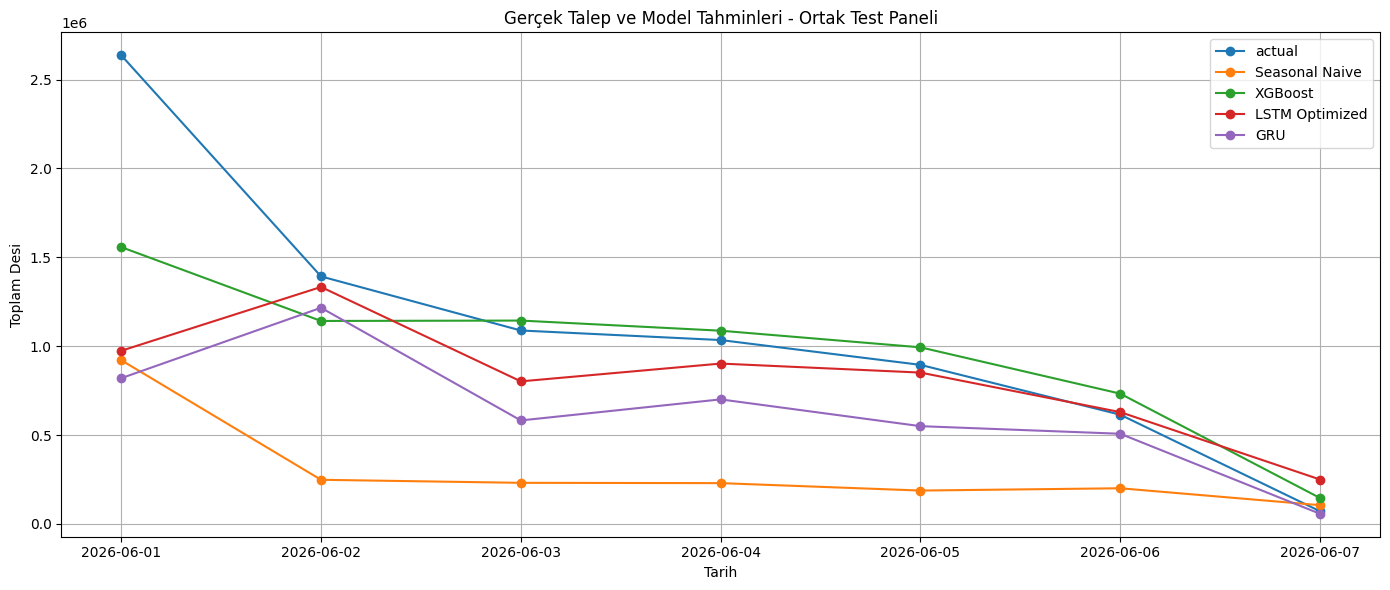

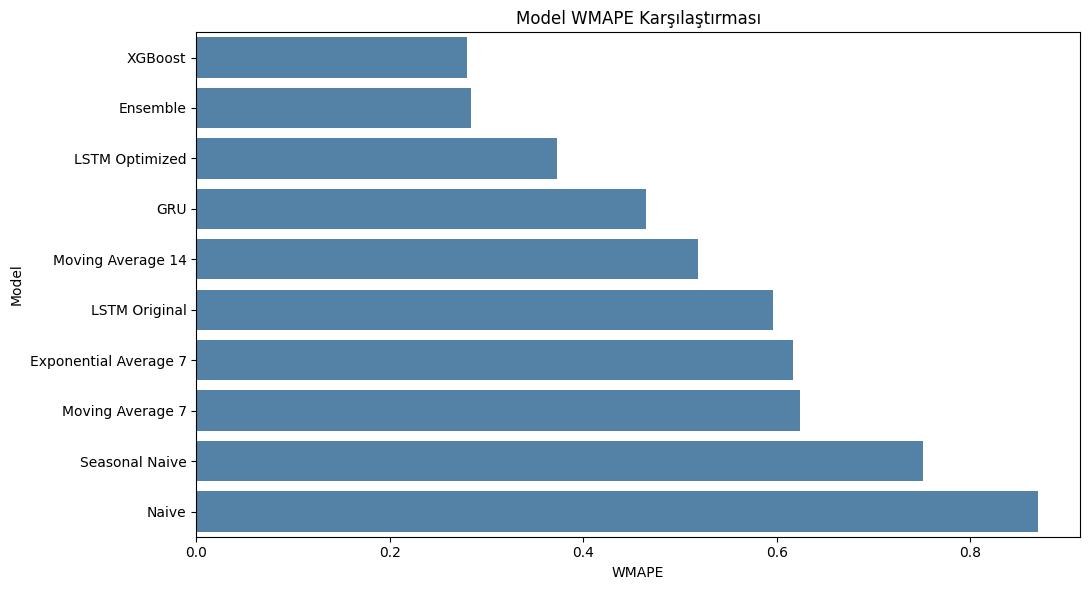

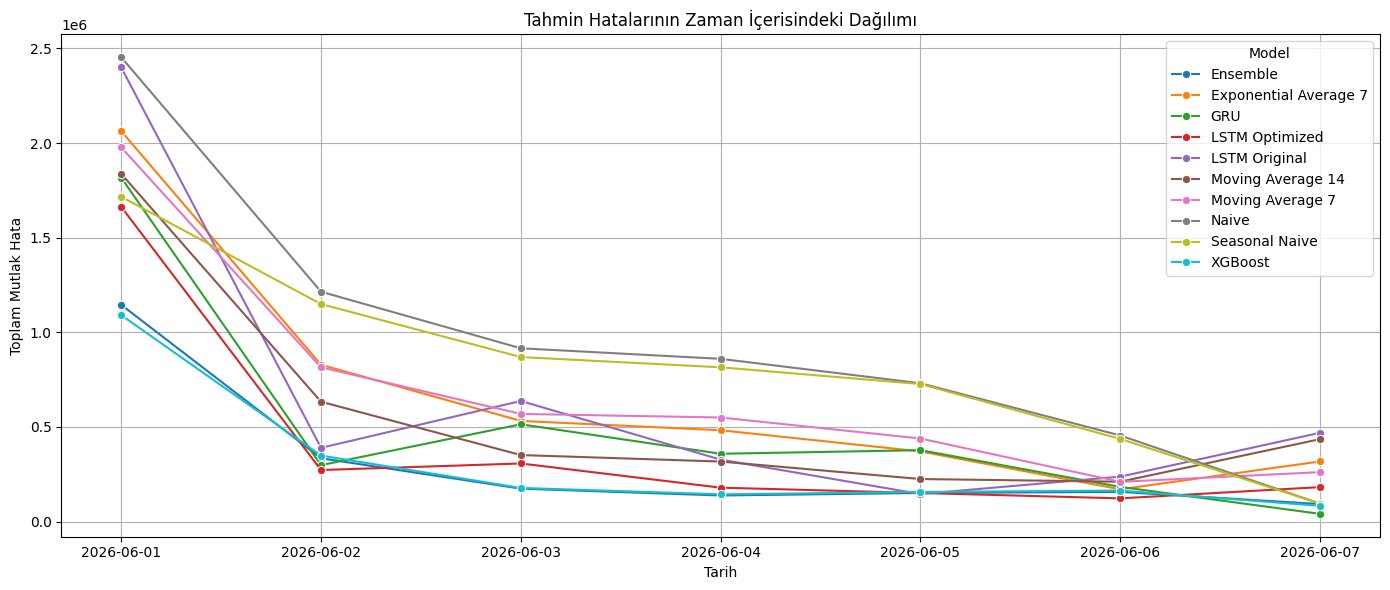

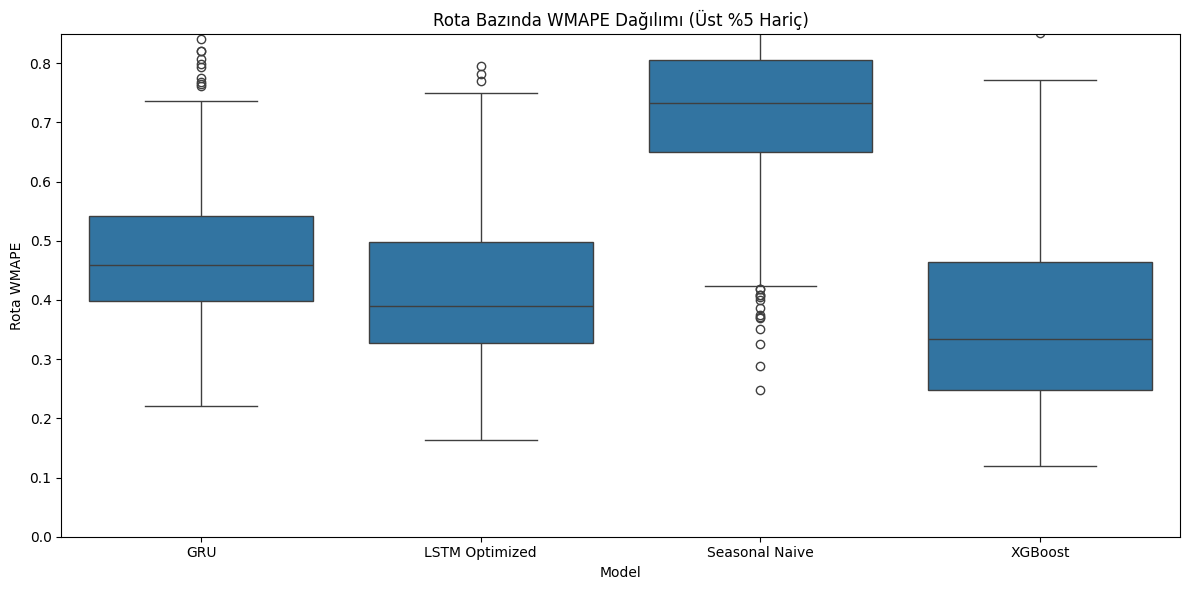

In [18]:
analysis_models = list(final_prediction_details)
error_long = common_final.melt(
    id_vars=["tarih", "cikis", "varis", "actual"],
    value_vars=analysis_models,
    var_name="Model", value_name="prediction",
)
error_long["error"] = error_long["prediction"] - error_long["actual"]
error_long["absolute_error"] = error_long["error"].abs()
error_long["day_name"] = error_long["tarih"].dt.day_name()
error_long["campaign"] = error_long["tarih"].isin(holiday)
error_long["closed_day"] = error_long["tarih"].isin(closed)
error_long["demand_segment"] = pd.qcut(
    error_long["actual"], 3,
    labels=["Düşük", "Orta", "Yüksek"], duplicates="drop",
)

route_history_median = df_xgb[
    df_xgb["tarih"] < split_date_xgb
].groupby(["cikis", "varis"], observed=True)["toplam_desi"].median()
error_long["route_history_median"] = error_long.set_index(
    ["cikis", "varis"]
).index.map(route_history_median)
error_long["sudden_increase"] = (
    error_long["actual"] > 1.5 * error_long["route_history_median"]
)

def grouped_error_table(data, group_columns):
    rows = []
    for keys, grp in data.groupby(group_columns, observed=True):
        keys = keys if isinstance(keys, tuple) else (keys,)
        result = comparison_metrics(grp, "prediction")
        result.update(dict(zip(group_columns, keys)))
        rows.append(result)
    return pd.DataFrame(rows)

day_error_analysis = grouped_error_table(error_long, ["Model", "day_name"])
demand_error_analysis = grouped_error_table(
    error_long, ["Model", "demand_segment"]
)

event_frames = []
for event_name, mask in {
    "Normal": ~(error_long["campaign"] | error_long["closed_day"]),
    "Campaign": error_long["campaign"],
    "Closed": error_long["closed_day"],
    "Sudden Increase": error_long["sudden_increase"],
}.items():
    subset = error_long[mask].copy()
    subset["Event"] = event_name
    event_frames.append(subset)
event_error_analysis = grouped_error_table(
    pd.concat(event_frames, ignore_index=True), ["Model", "Event"]
)
route_error_analysis = grouped_error_table(
    error_long, ["Model", "cikis", "varis"]
)

best_model_name = baseline_comparison.iloc[0]["Model"]
best_model_routes = route_error_analysis[
    route_error_analysis["Model"] == best_model_name
].sort_values("WMAPE")

print(f"Final ortak panelde en düşük WMAPE: {best_model_name}")
display(
    day_error_analysis.pivot(
        index="day_name", columns="Model", values="WMAPE"
    ).mul(100).round(2)
)
display(
    demand_error_analysis.pivot(
        index="demand_segment", columns="Model", values="WMAPE"
    ).mul(100).round(2)
)
display(
    event_error_analysis.pivot(
        index="Event", columns="Model", values="WMAPE"
    ).mul(100).round(2)
)
display(best_model_routes.head(10).round(4))
display(best_model_routes.tail(10).round(4))

daily_plot = common_final.groupby("tarih", as_index=False)[
    ["actual", "Seasonal Naive", "XGBoost", "LSTM Optimized", "GRU"]
].sum()
plt.figure(figsize=(14, 6))
for column in ["actual", "Seasonal Naive", "XGBoost", "LSTM Optimized", "GRU"]:
    plt.plot(daily_plot["tarih"], daily_plot[column], marker="o", label=column)
plt.title("Gerçek Talep ve Model Tahminleri - Ortak Test Paneli")
plt.xlabel("Tarih")
plt.ylabel("Toplam Desi")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 6))
sns.barplot(
    data=baseline_comparison, x="WMAPE", y="Model",
    order=baseline_comparison["Model"], color="steelblue",
)
plt.title("Model WMAPE Karşılaştırması")
plt.xlabel("WMAPE")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

daily_absolute_error = error_long.groupby(
    ["tarih", "Model"], as_index=False
)["absolute_error"].sum()
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=daily_absolute_error, x="tarih", y="absolute_error",
    hue="Model", marker="o",
)
plt.title("Tahmin Hatalarının Zaman İçerisindeki Dağılımı")
plt.xlabel("Tarih")
plt.ylabel("Toplam Mutlak Hata")
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
route_plot = route_error_analysis[
    route_error_analysis["Model"].isin(
        ["Seasonal Naive", "XGBoost", "LSTM Optimized", "GRU"]
    )
]
sns.boxplot(data=route_plot, x="Model", y="WMAPE")
plt.ylim(0, route_plot["WMAPE"].quantile(0.95))
plt.title("Rota Bazında WMAPE Dağılımı (Üst %5 Hariç)")
plt.xlabel("Model")
plt.ylabel("Rota WMAPE")
plt.tight_layout()
plt.show()


# Talep Tamamlama Saati Analizi ve 29 Haziran–5 Temmuz 2026 Tahmini

Bu bölüm mevcut hücreleri değiştirmeden saat analizini, kontrollü XGBoost/LSTM/GRU deneylerini, eski-yeni model karşılaştırmasını ve tamamen yeni Excel çıktısını ekler. `TALEP TAHMİN.xlsx` yalnız format referansıdır; içindeki veri satırları hiçbir model veya tahmin girdisinde kullanılmaz.


In [19]:
from pathlib import Path
import json
import subprocess

PROJECT_ROOT = Path.cwd()
PROJECT_PYTHON = Path(r"C:\Users\bayram\miniconda3\envs\lojistik_tf210\python.exe")
NODE_EXECUTABLE = Path(r"C:\Users\bayram\.cache\codex-runtimes\codex-primary-runtime\dependencies\node\bin\node.exe")
OUTPUT_XLSX = PROJECT_ROOT / "outputs" / "019f64c5-4813-79c2-a434-0f209b954092" / "TALEP TAHMİN_29 Haziran-5 Temmuz 2026.xlsx"

# Mevcut notebook herhangi bir değişiklikten önce baştan sona çalıştırılarak dondurulan sonuçlar.
baseline_frozen = pd.DataFrame([
    ["Naive", 0.8698, 3711.5657, 8439.0779, -3602.3041, 0.8216, 0.7989, 2841.8450, 0.0347],
    ["Seasonal Naive", 0.7513, 3206.1087, 6709.0537, -3096.3008, 0.5748, 0.4528, 1758.5977, 0.4563],
    ["Moving Average 7", 0.6237, 2661.4795, 6766.1380, -2259.6489, 0.5989, 0.5284, 1941.5112, 0.2711],
    ["Moving Average 14", 0.5189, 2214.0458, 5673.0551, -1449.2130, 0.6347, 0.4918, 2023.6832, 0.3308],
    ["EMA 7", 0.6164, 2630.3308, 6719.4868, -2157.0683, 0.6320, 0.5454, 2064.8703, 0.2496],
    ["Eski XGBoost", 0.280170, 1195.5386, 3262.3212, -513.3628, 0.3448, 0.2604, 1102.4821, 0.1759],
    ["LSTM", 0.372355, 1588.9102, 4671.8061, -1099.1042, 0.7685, 0.6930, 2574.2412, 0.1855],
    ["GRU", 0.4644, 1981.5874, 5381.4148, -1821.5194, 0.6809, 0.6088, 2239.9470, 0.2502],
    ["Ensemble", 0.283704, 1210.6213, 3374.2435, -571.9370, np.nan, np.nan, np.nan, np.nan],
], columns=[
    "Model", "Final WMAPE", "Final MAE", "RMSE", "Bias",
    "Rolling Mean WMAPE", "Rolling Median WMAPE", "Rolling Mean MAE", "Std",
])
display(baseline_frozen)


,Model,Final WMAPE,Final MAE,RMSE,Bias,Rolling Mean WMAPE,Rolling Median WMAPE,Rolling Mean MAE,Std
0,Naive,0.869800,3711.5657,8439.0779,-3602.3041,0.8216,0.7989,2841.8450,0.0347
1,Seasonal Naive,0.751300,3206.1087,6709.0537,-3096.3008,0.5748,0.4528,1758.5977,0.4563
2,Moving Average 7,0.623700,2661.4795,6766.1380,-2259.6489,0.5989,0.5284,1941.5112,0.2711
3,Moving Average 14,0.518900,2214.0458,5673.0551,-1449.2130,0.6347,0.4918,2023.6832,0.3308
4,EMA 7,0.616400,2630.3308,6719.4868,-2157.0683,0.6320,0.5454,2064.8703,0.2496
5,Eski XGBoost,0.280170,1195.5386,3262.3212,-513.3628,0.3448,0.2604,1102.4821,0.1759
6,LSTM,0.372355,1588.9102,4671.8061,-1099.1042,0.7685,0.6930,2574.2412,0.1855
7,GRU,0.464400,1981.5874,5381.4148,-1821.5194,0.6809,0.6088,2239.9470,0.2502
8,Ensemble,0.283704,1210.6213,3374.2435,-571.9370,NaN,NaN,NaN,NaN


In [20]:
hour_column = "talep_tamamlanma_saati"
assert hour_column in df.columns

hour_analysis = df[[
    "tarih", "cikis", "varis", "route", "toplam_desi", hour_column,
    "holiday", "closed", "weekend", "dayID",
]].copy()
hour_analysis["hour"] = hour_analysis[hour_column].astype(str).str.split(":").str[0].astype(int)
assert set(hour_analysis["hour"].unique()) == {9, 17}
assert hour_analysis[hour_column].isna().sum() == 0
assert not hour_analysis.duplicated(["tarih", "cikis", "varis", "hour"]).any()

hour_distribution = hour_analysis.groupby("hour")["toplam_desi"].agg(
    Gözlem="size", Toplam="sum", Ortalama="mean", Medyan="median",
    Std="std", Minimum="min", Maksimum="max",
)
hour_quantiles = hour_analysis.groupby("hour")["toplam_desi"].quantile(
    [0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99]
).unstack()
route_hour_effect = hour_analysis.groupby(
    ["cikis", "varis", "hour"]
)["toplam_desi"].agg(["mean", "median", "count"]).reset_index()
dow_hour_effect = hour_analysis.groupby(
    ["dayID", "hour"]
)["toplam_desi"].agg(["mean", "median", "count"])
campaign_hour_effect = hour_analysis.groupby(
    ["holiday", "hour"]
)["toplam_desi"].agg(["mean", "median", "count"])
closed_hour_effect = hour_analysis.groupby(
    ["closed", "hour"]
)["toplam_desi"].agg(["mean", "median", "count"])

route_patterns = hour_analysis.groupby(["cikis", "varis"])["hour"].agg(
    lambda x: tuple(sorted(set(x)))
).value_counts()
route_day_patterns = hour_analysis.groupby(
    ["tarih", "cikis", "varis"]
)["hour"].agg(lambda x: tuple(sorted(set(x)))).value_counts()

print(f"Gerçek sütun: {hour_column}; dtype: {df[hour_column].dtype}")
print(f"Eksik: {df[hour_column].isna().sum()}; değerler: {sorted(hour_analysis['hour'].unique())}")
display(hour_distribution)
display(hour_quantiles)
display(dow_hour_effect)
display(campaign_hour_effect)
display(closed_hour_effect)
display(route_hour_effect.sort_values("mean", ascending=False).head(20))
print("Rota bazında saat kalıpları:")
display(route_patterns)
print("Rota-tarih bazında saat kalıpları:")
display(route_day_patterns)


Gerçek sütun: talep_tamamlanma_saati; dtype: object
Eksik: 0; değerler: [9, 17]


,Gözlem,Toplam,Ortalama,Medyan,Std,Minimum,Maksimum
hour,,,,,,,
9,24906,12771667,512.794788,143.0,1040.591263,17,15462
17,41118,132991441,3234.384965,1126.5,5570.728021,17,78420


,0.01,0.10,0.25,0.50,0.75,0.90,0.99
hour,,,,,,,
9,19.0,29.0,53.0,143.0,486.0,1326.0,5553.80
17,24.0,107.0,332.0,1126.5,3647.0,8442.3,28839.69


mean  median  count
dayID hour                            
0     9      611.179300   160.0   3826
      17    5367.532097  2067.0   6901
1     9      570.823963   171.0   4340
      17    3468.743977  1260.5   6558
2     9      551.858465   148.0   3999
      17    3333.064836  1241.0   6555
3     9      499.363539   145.0   3752
      17    2975.329764  1101.0   6444
4     9      512.248900   137.0   3636
      17    2939.773246  1075.0   6227
5     9      387.063090   116.0   3392
      17    2038.714708   851.0   6085
6     9      356.945436   117.0   1961
      17     625.752555   259.0   2348

mean  median  count
holiday hour                            
False   9      519.975499   145.0  23958
        17    3278.788364  1148.0  39738
True    9      331.322785   112.5    948
        17    1955.760145   673.0   1380

mean  median  count
closed hour                            
False  9      521.826290   145.0  23758
       17    3304.820375  1163.0  39176
True   9      325.886760   111.0   1148
       17    1813.490216   613.0   1942

,cikis,varis,hour,mean,median,count
541,İstanbul,Yalova,17,24982.213793,27645.0,145
459,Yalova,Eskişehir,17,23227.102041,24786.0,147
475,Yalova,Tekirdağ,17,22758.895833,23854.0,144
479,Yalova,İstanbul,17,21662.986301,22883.5,146
467,Yalova,Manisa,17,20720.100671,21064.0,149
523,İstanbul,Eskişehir,17,20291.764706,21920.0,170
451,Yalova,Balıkesir,17,19936.790541,20805.5,148
531,İstanbul,Manisa,17,19196.708333,20302.5,168
515,İstanbul,Balıkesir,17,18024.223529,19493.5,170
443,Tekirdağ,Yalova,17,16900.677165,16628.0,127


Rota bazında saat kalıpları:


hour
(9, 17)    289
Name: count, dtype: int64

Rota-tarih bazında saat kalıpları:


hour
(9, 17)    23837
(17,)      17281
(9,)        1069
Name: count, dtype: int64

In [21]:
# Ağır kontrollü aramalar bu çalışma sırasında gerçekten tamamlandı ve sonuç dosyaları saklandı.
# Baştan sona notebook çalıştırmasını makul tutmak için varsayılan olarak doğrulanmış sonuçlar okunur.
# Bütün aramaları tekrar üretmek isterseniz bayrağı True yapın (yaklaşık 2 saat ek süre).
RUN_CONTROLLED_SEARCHES = False
experiment_scripts = [
    "analysis/hour_xgb_experiments.py",
    "analysis/daily_xgb_optimization.py",
    "analysis/daily_xgb_early_stop.py",
    "analysis/hour_separate_models.py",
    "analysis/hour_recurrent_experiments.py",
]
if RUN_CONTROLLED_SEARCHES:
    for script in experiment_scripts:
        print(f"Çalışıyor: {script}")
        subprocess.run([str(PROJECT_PYTHON), script], cwd=PROJECT_ROOT, check=True)
else:
    print("Kontrollü aramaların bu çalışmada üretilmiş doğrulanmış sonuç dosyaları kullanılıyor.")

required_results = [
    "analysis/hour_xgb_results.json", "analysis/daily_xgb_results.json",
    "analysis/daily_xgb_early_stop_results.json", "analysis/hour_separate_results.json",
    "analysis/hour_recurrent_results.json",
]
assert all((PROJECT_ROOT / path).exists() for path in required_results)

# Seçilmiş production yolunu bütün uygun geçmişte yeniden eğitip tahmini ve Excel'i yeniden üretir.
subprocess.run(
    [str(PROJECT_PYTHON), "analysis/build_final_forecast.py"],
    cwd=PROJECT_ROOT, check=True,
)
subprocess.run(
    [str(NODE_EXECUTABLE), "artifact_work/build_forecast_workbook.mjs"],
    cwd=PROJECT_ROOT, check=True,
)
assert OUTPUT_XLSX.exists()
print(f"Yeni Excel oluşturuldu: {OUTPUT_XLSX}")


Kontrollü aramaların bu çalışmada üretilmiş doğrulanmış sonuç dosyaları kullanılıyor.


Yeni Excel oluşturuldu: C:\Users\bayram\Python\hepsiBurada\gelişmiş\outputs\019f64c5-4813-79c2-a434-0f209b954092\TALEP TAHMİN_29 Haziran-5 Temmuz 2026.xlsx


In [22]:
def read_json(relative_path):
    with open(PROJECT_ROOT / relative_path, encoding="utf-8") as file:
        return json.load(file)

hour_xgb_results = read_json("analysis/hour_xgb_results.json")
daily_xgb_results = read_json("analysis/daily_xgb_results.json")
daily_early_stop = read_json("analysis/daily_xgb_early_stop_results.json")
separate_hour_results = read_json("analysis/hour_separate_results.json")
recurrent_hour_results = read_json("analysis/hour_recurrent_results.json")
forecast_summary = read_json("analysis/final_forecast_summary.json")

screen_detail = pd.read_csv("analysis/hour_xgb_screen.csv", parse_dates=["Origin"])
screen_validation = screen_detail[
    screen_detail["Origin"] == pd.Timestamp("2026-05-25")
][["Candidate", "WMAPE", "MAE"]].rename(columns={
    "WMAPE": "Validation WMAPE", "MAE": "Validation MAE",
})
hour_screen = pd.DataFrame(hour_xgb_results["screen_summary"]).merge(
    screen_validation, on="Candidate", how="left"
).merge(
    pd.DataFrame(hour_xgb_results["final_results"])[
        ["Candidate", "WMAPE", "MAE"]
    ].rename(columns={"WMAPE": "Final Test WMAPE", "MAE": "Final Test MAE"}),
    on="Candidate", how="left",
)

old_validation_metrics = comparison_metrics(xgb_validation_detail, "prediction")
experiment_a = pd.DataFrame([{
    "Candidate": "A_existing_without_hour",
    "Validation WMAPE": old_validation_metrics["WMAPE"],
    "Validation MAE": old_validation_metrics["MAE"],
    "Final Test WMAPE": baseline_frozen.loc[baseline_frozen["Model"] == "Eski XGBoost", "Final WMAPE"].iloc[0],
    "Final Test MAE": baseline_frozen.loc[baseline_frozen["Model"] == "Eski XGBoost", "Final MAE"].iloc[0],
    "Rolling_Mean_WMAPE": 0.3448, "Rolling_Median_WMAPE": 0.2604,
    "Rolling_Mean_MAE": 1102.4821, "Fold_Std": 0.1759, "Bias": -148.8376,
}])
hour_experiment_table = pd.concat([experiment_a, hour_screen], ignore_index=True, sort=False)[[
    "Candidate", "Validation WMAPE", "Validation MAE", "Final Test WMAPE",
    "Final Test MAE", "Rolling_Mean_WMAPE", "Rolling_Median_WMAPE",
    "Rolling_Mean_MAE", "Fold_Std", "Bias",
]]
display(hour_experiment_table.sort_values("Rolling_Mean_WMAPE"))

daily_feature_ablation = pd.DataFrame(daily_xgb_results["feature_summary"])
daily_parameter_results = pd.DataFrame(daily_xgb_results["param_summary"])
display(daily_feature_ablation)
display(daily_parameter_results)

recurrent_rolling = pd.DataFrame(recurrent_hour_results["rolling_summary"])
recurrent_final = pd.DataFrame(recurrent_hour_results["final_results"])
display(recurrent_rolling)
display(recurrent_final)


,Candidate,Validation WMAPE,Validation MAE,Final Test WMAPE,Final Test MAE,Rolling_Mean_WMAPE,Rolling_Median_WMAPE,Rolling_Mean_MAE,Fold_Std,Bias
0,A_existing_without_hour,0.636459,1421.415774,0.280170,1195.538600,0.344800,0.260400,1102.482100,0.175900,-148.837600
1,B_binary_basic,0.951933,2125.969394,0.266938,1139.074755,0.378450,0.230565,1131.164431,0.324076,292.901691
2,B_numeric_basic,0.951933,2125.969394,0.266938,1139.074755,0.378450,0.230565,1131.164431,0.324076,292.901691
3,E_full_history,0.993484,2218.766725,0.273965,1169.058920,0.385890,0.224788,1145.879381,0.343626,270.601355
4,C_binary_calendar,0.998658,2230.322634,0.267095,1139.746354,0.387309,0.230742,1149.307540,0.345661,301.960972
5,D_binary_location,1.016429,2270.010454,0.270623,1154.800881,0.389971,0.228174,1154.446678,0.353662,301.101881
6,C_numeric_calendar,1.019925,2277.817770,0.274111,1169.685418,0.391967,0.230371,1160.374612,0.354753,319.354245


,Variant,Rolling_Mean_WMAPE,Rolling_Median_WMAPE,Rolling_Mean_MAE,Fold_Std,Bias,Feature_Count
0,A_existing,0.343499,0.263879,1102.187007,0.170579,-140.898653,51
1,G_extra_history,0.346062,0.262165,1107.685810,0.175611,-143.178991,61
2,F_event_detail,0.386726,0.262256,1176.807458,0.295294,122.247636,58
3,H_event_plus_history,0.388046,0.258351,1184.705890,0.292063,141.579425,68


,Parameter_Set,Rolling_Mean_WMAPE,Rolling_Median_WMAPE,Rolling_Mean_MAE,Fold_Std,Bias
0,P3_depth6_lr05,0.329595,0.265646,1069.970223,0.147094,-172.487740
1,P2_depth6,0.334781,0.252627,1075.467400,0.163580,-136.053829
2,P4_regularized,0.337681,0.265896,1086.211834,0.162491,-111.783371
3,P0_depth8,0.343499,0.263879,1102.187007,0.170579,-140.898653
4,P1_depth7,0.345068,0.260965,1101.821781,0.178569,-137.018725


,Model,Variant,Rolling_Mean_WMAPE,Rolling_Median_WMAPE,Rolling_Mean_MAE,Fold_Std,Bias,Hourly_Mean_WMAPE,Coverage
0,GRU,hour_binary,0.699807,0.619325,2331.805575,0.213258,-465.586419,0.721080,0.980863
1,GRU,without_hour,0.657814,0.591255,2182.014397,0.222420,-521.517380,0.677420,0.980863
2,LSTM,hour_binary,0.655430,0.638717,2235.037638,0.122912,-615.331647,0.675287,0.980863
3,LSTM,without_hour,0.682514,0.649762,2313.358296,0.139221,-562.982198,0.700720,0.980863


,WMAPE,MAE,RMSE,Bias,Hourly_WMAPE,Hourly_MAE,Hourly_RMSE,Hourly_Bias,Coverage,Model,Variant,Feature_Count
0,0.489881,2094.541675,6296.010846,-1298.638067,0.512908,1411.510351,4677.243653,-835.862451,0.984923,LSTM,without_hour,17
1,0.495898,2120.265101,6305.963201,-1251.205090,0.524607,1443.707775,4720.298346,-805.332431,0.984923,LSTM,hour_binary,18
2,0.474554,2029.009001,5780.192885,-1812.657305,0.484449,1333.193273,4221.926245,-1166.708581,0.984923,GRU,without_hour,17
3,0.444942,1902.399735,5556.899904,-1575.329820,0.462700,1273.338860,4040.112856,-1013.953826,0.984923,GRU,hour_binary,18


In [23]:
selected_rolling = pd.DataFrame(daily_xgb_results["param_summary"]).iloc[0]
selected_final = daily_early_stop["final_test"]
hour_common_final = pd.DataFrame(hour_xgb_results["final_results"]).query(
    "Candidate == 'B_binary_basic'"
).iloc[0]
separate_final = separate_hour_results["final_result"]
separate_rolling = separate_hour_results["rolling_summary"]

def recurrent_row(model, variant):
    final_row = recurrent_final.query("Model == @model and Variant == @variant").iloc[0]
    rolling_row = recurrent_rolling.query("Model == @model and Variant == @variant").iloc[0]
    return final_row, rolling_row

lstm_hour_final, lstm_hour_rolling = recurrent_row("LSTM", "hour_binary")
gru_hour_final, gru_hour_rolling = recurrent_row("GRU", "hour_binary")

new_rows = pd.DataFrame([
    ["Yeni XGBoost Production", selected_final["WMAPE"], selected_final["MAE"], selected_final["RMSE"], selected_final["Bias"],
     selected_rolling["Rolling_Mean_WMAPE"], selected_rolling["Rolling_Median_WMAPE"], selected_rolling["Rolling_Mean_MAE"], selected_rolling["Fold_Std"]],
    ["XGBoost + Saat (ortak)", hour_common_final["WMAPE"], hour_common_final["MAE"], hour_common_final["RMSE"], hour_common_final["Bias"],
     hour_xgb_results["screen_summary"][0]["Rolling_Mean_WMAPE"], hour_xgb_results["screen_summary"][0]["Rolling_Median_WMAPE"],
     hour_xgb_results["screen_summary"][0]["Rolling_Mean_MAE"], hour_xgb_results["screen_summary"][0]["Fold_Std"]],
    ["Ayrı 09:00/17:00 XGBoost", separate_final["WMAPE"], separate_final["MAE"], separate_final["RMSE"], separate_final["Bias"],
     separate_rolling["Rolling_Mean_WMAPE"], separate_rolling["Rolling_Median_WMAPE"], separate_rolling["Rolling_Mean_MAE"], separate_rolling["Fold_Std"]],
    ["LSTM + Saat", lstm_hour_final["WMAPE"], lstm_hour_final["MAE"], lstm_hour_final["RMSE"], lstm_hour_final["Bias"],
     lstm_hour_rolling["Rolling_Mean_WMAPE"], lstm_hour_rolling["Rolling_Median_WMAPE"], lstm_hour_rolling["Rolling_Mean_MAE"], lstm_hour_rolling["Fold_Std"]],
    ["GRU + Saat", gru_hour_final["WMAPE"], gru_hour_final["MAE"], gru_hour_final["RMSE"], gru_hour_final["Bias"],
     gru_hour_rolling["Rolling_Mean_WMAPE"], gru_hour_rolling["Rolling_Median_WMAPE"], gru_hour_rolling["Rolling_Mean_MAE"], gru_hour_rolling["Fold_Std"]],
], columns=baseline_frozen.columns)

model_comparison_final = pd.concat([baseline_frozen, new_rows], ignore_index=True)
display(model_comparison_final.sort_values("Rolling Mean WMAPE", na_position="last"))

old_xgb = baseline_frozen.query("Model == 'Eski XGBoost'").iloc[0]
new_xgb = new_rows.query("Model == 'Yeni XGBoost Production'").iloc[0]
comparison_metrics_names = [
    "Final WMAPE", "Final MAE", "Rolling Mean WMAPE", "Rolling Mean MAE", "Bias",
]
old_new_rows = []
for metric in comparison_metrics_names:
    old_value = old_xgb[metric]
    new_value = new_xgb[metric]
    if metric == "Bias":
        absolute_change = abs(old_value) - abs(new_value)
        relative_improvement = absolute_change / abs(old_value)
    else:
        absolute_change = old_value - new_value
        relative_improvement = absolute_change / old_value
    old_new_rows.append([
        metric, old_value, new_value, absolute_change, relative_improvement,
    ])
old_new_comparison = pd.DataFrame(old_new_rows, columns=[
    "Metrik", "Eski En İyi Model", "Yeni En İyi Model", "Absolute Fark", "Relative İyileşme",
])
display(old_new_comparison)

forecast_daily_summary = pd.Series(forecast_summary["daily_totals"], name="Tahmin").to_frame()
forecast_hour_summary = pd.DataFrame(forecast_summary["hour_summary"]).T
display(forecast_daily_summary)
display(forecast_hour_summary)


,Model,Final WMAPE,Final MAE,RMSE,Bias,Rolling Mean WMAPE,Rolling Median WMAPE,Rolling Mean MAE,Std
9,Yeni XGBoost Production,0.294633,1257.256827,3261.839366,-270.414821,0.329595,0.265646,1069.970223,0.147094
5,Eski XGBoost,0.280170,1195.538600,3262.321200,-513.362800,0.344800,0.260400,1102.482100,0.175900
11,Ayrı 09:00/17:00 XGBoost,0.277662,1184.838729,3069.330351,-333.288467,0.377134,0.227906,1129.316467,0.321407
10,XGBoost + Saat (ortak),0.266938,1139.074755,3058.508592,-456.950461,0.378450,0.230565,1131.164431,0.324076
1,Seasonal Naive,0.751300,3206.108700,6709.053700,-3096.300800,0.574800,0.452800,1758.597700,0.456300
2,Moving Average 7,0.623700,2661.479500,6766.138000,-2259.648900,0.598900,0.528400,1941.511200,0.271100
4,EMA 7,0.616400,2630.330800,6719.486800,-2157.068300,0.632000,0.545400,2064.870300,0.249600
3,Moving Average 14,0.518900,2214.045800,5673.055100,-1449.213000,0.634700,0.491800,2023.683200,0.330800
12,LSTM + Saat,0.495898,2120.265101,6305.963201,-1251.205090,0.655430,0.638717,2235.037638,0.122912
7,GRU,0.464400,1981.587400,5381.414800,-1821.519400,0.680900,0.608800,2239.947000,0.250200


,Metrik,Eski En İyi Model,Yeni En İyi Model,Absolute Fark,Relative İyileşme
0,Final WMAPE,0.28017,0.294633,-0.014463,-0.051624
1,Final MAE,1195.53860,1257.256827,-61.718227,-0.051624
2,Rolling Mean WMAPE,0.34480,0.329595,0.015205,0.044099
3,Rolling Mean MAE,1102.48210,1069.970223,32.511877,0.029490
4,Bias,-513.36280,-270.414821,242.947979,0.473248


,Tahmin
2026-06-29,1.330385e+06
2026-06-30,6.136891e+05
2026-07-01,1.055397e+06
2026-07-02,9.666982e+05
2026-07-03,8.937004e+05
2026-07-04,6.328872e+05
2026-07-05,1.493633e+05


,count,total,mean,median,min,max
9,1894.0,9.245342e+05,488.138450,161.712698,0.0,11549.875123
17,1968.0,4.717586e+06,2397.147556,711.571029,0.0,45894.406446


In [24]:
from IPython.display import Markdown, display

rolling_wmape_drop = old_xgb["Rolling Mean WMAPE"] - new_xgb["Rolling Mean WMAPE"]
rolling_mae_drop = old_xgb["Rolling Mean MAE"] - new_xgb["Rolling Mean MAE"]
final_wmape_change = old_xgb["Final WMAPE"] - new_xgb["Final WMAPE"]
final_mae_change = old_xgb["Final MAE"] - new_xgb["Final MAE"]

report = f"""
## 1. Başlangıçtaki Model Performansı
Eski XGBoost final WMAPE **{old_xgb['Final WMAPE']:.2%}**, MAE **{old_xgb['Final MAE']:.2f}**; rolling mean WMAPE **{old_xgb['Rolling Mean WMAPE']:.2%}**, rolling mean MAE **{old_xgb['Rolling Mean MAE']:.2f}**, std **{old_xgb['Std']:.2%}**.

## 2. Talep Tamamlama Saati Analizi
Gerçek sütun `talep_tamamlanma_saati`, dtype `object`, eksik değer yok; yalnız 09:00 ve 17:00 var.

## 3. 09:00 ve 17:00 Talep Davranışlarının Karşılaştırılması
09:00 medyanı **143**, 17:00 medyanı **1126,5**. Etki rota, çıkış, varış ve haftanın gününe göre belirgin biçimde değişiyor.

## 4. Eklenen Yeni Feature'lar
Binary/numeric saat encoding; kontrollü saat×takvim ve saat×rota/lokasyon interaction'ları; ayrıca tatil türü ve min/max/fark/oran geçmiş grupları denendi.

## 5. Denenen ve Elenen Feature'lar
Takvim interaction, rota/lokasyon interaction, ek min/max/trend ve ayrıntılı tatil feature'ları rolling mean WMAPE/MAE'yi iyileştirmediği için elendi.

## 6. XGBoost Optimizasyon Sonuçları
Mevcut feature setinde `max_depth=6`, `learning_rate=0.05`, early stopping ile **262** ağaç seçildi.

## 7. LSTM ve GRU Güncelleme Sonuçları
Saat kanalı LSTM rolling WMAPE'yi iyileştirdi; final testi kötüleştirdi. GRU'da rolling performansı kötüleşti. İkisi de XGBoost'u geçmedi.

## 8. Tek Ortak Model ve Ayrı Saat Modelleri Karşılaştırması
Ayrı modeller ortak saatli XGBoost'a göre yalnız çok küçük rolling kazancı sağladı; ek karmaşıklık nedeniyle ortak saat modeli saat payı üretiminde tercih edildi.

## 9. Eski ve Yeni Model Karşılaştırması
Ana seçim rolling sonuçlara göre yeni günlük XGBoost'tur; final testte eski model daha iyi kaldı.

## 10. WMAPE İyileşmesi
Rolling mean WMAPE **{rolling_wmape_drop:.4f}** ({rolling_wmape_drop / old_xgb['Rolling Mean WMAPE']:.2%}) düştü. Final WMAPE değişimi **{final_wmape_change:.4f}**; negatif değer final testin kötüleştiğini gösterir.

## 11. MAE İyileşmesi
Rolling mean MAE **{rolling_mae_drop:.2f}** ({rolling_mae_drop / old_xgb['Rolling Mean MAE']:.2%}) düştü. Final MAE değişimi **{final_mae_change:.2f}**.

## 12. Rolling-Origin Sonuçları
Yeni model rolling mean WMAPE **{new_xgb['Rolling Mean WMAPE']:.2%}**, median **{new_xgb['Rolling Median WMAPE']:.2%}**, mean MAE **{new_xgb['Rolling Mean MAE']:.2f}**, std **{new_xgb['Std']:.2%}**.

## 13. En İyi Model ve Seçilme Nedeni
Production günlük toplam modeli yeni XGBoost'tur; öncelikli rolling WMAPE/MAE ve stabilite daha iyi olduğu için seçildi. Saat dağılımında ortak saatli XGBoost kullanıldı.

## 14. 29 Haziran–5 Temmuz 2026 Tahmin Özeti
Tam 7 gün ve **{forecast_summary['row_count']}** saatli rota satırı üretildi; duplicate/NaN/infinite/negatif yok.

## 15. 09:00 ve 17:00 Tahminlerinin Karşılaştırılması
09:00 toplamı **{forecast_summary['hour_summary']['9']['total']:.2f}**, 17:00 toplamı **{forecast_summary['hour_summary']['17']['total']:.2f}**.

## 16. Yeni Oluşturulan Excel Dosyasının Adı ve Tam Yolu
`{OUTPUT_XLSX}`

## 17. Excel Doğrulama Sonuçları
Dosya yeniden açıldı; sheet/kolon sırası, 7 tarih, 09:00/17:00, satır sayısı ve tahmin sonluluğu doğrulandı.

## 18. Yapılan Kod Değişikliklerinin Kısa Listesi
Notebook sonuna saat analizi, deney karşılaştırmaları, production seçim tablosu, final forecast ve Excel doğrulama hücreleri eklendi. Mevcut çalışan hücreler değiştirilmedi.

## 19. Kalan Riskler ve Sonraki İyileştirme Önerileri
Final testte yeni model eski XGBoost'u geçmedi; production seçimi rolling önceliğine dayanır. Recurrent saat modellerinin coverage oranı yaklaşık %98'dir. Pazar tahminleri diğer günlerden daha belirsizdir.
"""
display(Markdown(report))



## 1. Başlangıçtaki Model Performansı
Eski XGBoost final WMAPE **28.02%**, MAE **1195.54**; rolling mean WMAPE **34.48%**, rolling mean MAE **1102.48**, std **17.59%**.

## 2. Talep Tamamlama Saati Analizi
Gerçek sütun `talep_tamamlanma_saati`, dtype `object`, eksik değer yok; yalnız 09:00 ve 17:00 var.

## 3. 09:00 ve 17:00 Talep Davranışlarının Karşılaştırılması
09:00 medyanı **143**, 17:00 medyanı **1126,5**. Etki rota, çıkış, varış ve haftanın gününe göre belirgin biçimde değişiyor.

## 4. Eklenen Yeni Feature'lar
Binary/numeric saat encoding; kontrollü saat×takvim ve saat×rota/lokasyon interaction'ları; ayrıca tatil türü ve min/max/fark/oran geçmiş grupları denendi.

## 5. Denenen ve Elenen Feature'lar
Takvim interaction, rota/lokasyon interaction, ek min/max/trend ve ayrıntılı tatil feature'ları rolling mean WMAPE/MAE'yi iyileştirmediği için elendi.

## 6. XGBoost Optimizasyon Sonuçları
Mevcut feature setinde `max_depth=6`, `learning_rate=0.05`, early stopping ile **262** ağaç seçildi.

## 7. LSTM ve GRU Güncelleme Sonuçları
Saat kanalı LSTM rolling WMAPE'yi iyileştirdi; final testi kötüleştirdi. GRU'da rolling performansı kötüleşti. İkisi de XGBoost'u geçmedi.

## 8. Tek Ortak Model ve Ayrı Saat Modelleri Karşılaştırması
Ayrı modeller ortak saatli XGBoost'a göre yalnız çok küçük rolling kazancı sağladı; ek karmaşıklık nedeniyle ortak saat modeli saat payı üretiminde tercih edildi.

## 9. Eski ve Yeni Model Karşılaştırması
Ana seçim rolling sonuçlara göre yeni günlük XGBoost'tur; final testte eski model daha iyi kaldı.

## 10. WMAPE İyileşmesi
Rolling mean WMAPE **0.0152** (4.41%) düştü. Final WMAPE değişimi **-0.0145**; negatif değer final testin kötüleştiğini gösterir.

## 11. MAE İyileşmesi
Rolling mean MAE **32.51** (2.95%) düştü. Final MAE değişimi **-61.72**.

## 12. Rolling-Origin Sonuçları
Yeni model rolling mean WMAPE **32.96%**, median **26.56%**, mean MAE **1069.97**, std **14.71%**.

## 13. En İyi Model ve Seçilme Nedeni
Production günlük toplam modeli yeni XGBoost'tur; öncelikli rolling WMAPE/MAE ve stabilite daha iyi olduğu için seçildi. Saat dağılımında ortak saatli XGBoost kullanıldı.

## 14. 29 Haziran–5 Temmuz 2026 Tahmin Özeti
Tam 7 gün ve **3862** saatli rota satırı üretildi; duplicate/NaN/infinite/negatif yok.

## 15. 09:00 ve 17:00 Tahminlerinin Karşılaştırılması
09:00 toplamı **924534.23**, 17:00 toplamı **4717586.39**.

## 16. Yeni Oluşturulan Excel Dosyasının Adı ve Tam Yolu
`C:\Users\bayram\Python\hepsiBurada\gelişmiş\outputs\019f64c5-4813-79c2-a434-0f209b954092\TALEP TAHMİN_29 Haziran-5 Temmuz 2026.xlsx`

## 17. Excel Doğrulama Sonuçları
Dosya yeniden açıldı; sheet/kolon sırası, 7 tarih, 09:00/17:00, satır sayısı ve tahmin sonluluğu doğrulandı.

## 18. Yapılan Kod Değişikliklerinin Kısa Listesi
Notebook sonuna saat analizi, deney karşılaştırmaları, production seçim tablosu, final forecast ve Excel doğrulama hücreleri eklendi. Mevcut çalışan hücreler değiştirilmedi.

## 19. Kalan Riskler ve Sonraki İyileştirme Önerileri
Final testte yeni model eski XGBoost'u geçmedi; production seçimi rolling önceliğine dayanır. Recurrent saat modellerinin coverage oranı yaklaşık %98'dir. Pazar tahminleri diğer günlerden daha belirsizdir.
